# Taller 2. Predicción de abandono (churn) de clientes
## Notebook 2 de 2. Modelado y evaluación

**MINE-4101 Ciencia de Datos Aplicada, Universidad de los Andes, 2026-20**

**Integrantes:**
* Lina Muñoz (202310172)
* Yair Andrade (20231)

**Requisito.** Este notebook parte del archivo `data/churn_limpio.csv`, generado por `01_entendimiento_preparacion.ipynb`. Ese notebook debe ejecutarse primero.

**Contenido**
* 0. Configuración del entorno
* 2. Entrenamiento de modelos de Machine Learning
* 3. Análisis cuantitativo de resultados
* 4. Análisis cualitativo de resultados

## 0. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.3f}".format)

print(f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}")

pandas 2.3.3, scikit-learn 1.7.2


## 2. Entrenamiento de modelos de Machine Learning

El objetivo es construir un modelo que prediga si un cliente abandonará el banco (`churn = 1`). Entrenamos y comparamos tres modelos:
* **Regresión logística**, como modelo básico e interpretable.
* **Random Forest** y **Gradient Boosting**, como modelos de ensamble, capaces de capturar relaciones no lineales e interacciones entre variables.

Además, comparamos dos conjuntos de variables, las originales y un conjunto ampliado con variables derivadas a partir de la práctica del curso y de los hallazgos del EDA.

### 2.1 Carga de los datos limpios

Cargamos el resultado del notebook 1 y verificamos que tenga las dimensiones y los faltantes esperados. Los valores faltantes todavía no se han imputado. Eso se hará más adelante usando solo el conjunto de entrenamiento.

In [2]:
df = pd.read_csv("data/churn_limpio.csv")

print(f"Dimensiones: {df.shape}")
print(f"Tasa de churn: {df['churn'].mean():.1%}\n")
print("Valores faltantes por variable:")
print(df.isna().sum()[df.isna().sum() > 0])

Dimensiones: (10000, 11)
Tasa de churn: 20.4%

Valores faltantes por variable:
credit_score        254
age                 306
tenure                2
balance             200
estimated_salary    353
dtype: int64


### 2.2 Ingeniería de características

Creamos variables nuevas a partir de las existentes, con el fin de representar de forma explícita algunos patrones que encontramos en el EDA, estas caracteristicas las sacamos de las planteadas en la practica del curso. Esto es especialmente útil para la regresión logística, que solo puede modelar relaciones monótonas.

| Variable nueva | Definición | Hallazgo del EDA que la motiva |
|---|---|---|
| `balance_cero` | 1 si el saldo es 0 | El saldo forma dos grupos separados (sección 1.7.1) |
| `balance_salario` | Saldo dividido entre el salario estimado más 1 | Relación entre lo que el cliente tiene en el banco y sus ingresos |
| `productos_1` | 1 si tiene un solo producto | Churn de 28% con 1 producto frente a 8% con 2 (sección 1.8.2) |
| `productos_3mas` | 1 si tiene 3 o más productos | Churn de más del 80% con 3 o 4 productos (sección 1.8.2) |
| `edad_activo` | Edad multiplicada por `active_member` | Combina las dos variables con mayor relación lineal con el churn |

In [3]:
df["balance_cero"] = np.where(df["balance"].isna(), np.nan, (df["balance"] == 0).astype(float))
df["balance_salario"] = df["balance"] / (df["estimated_salary"] + 1)
df["productos_1"] = (df["products_number"] == 1).astype(int)
df["productos_3mas"] = (df["products_number"] >= 3).astype(int)
df["edad_activo"] = df["age"] * df["active_member"]

df[["balance", "estimated_salary", "products_number", "age", "active_member",
    "balance_cero", "balance_salario", "productos_1", "productos_3mas", "edad_activo"]].head()

,balance,estimated_salary,products_number,age,active_member,balance_cero,balance_salario,productos_1,productos_3mas,edad_activo
0,0.000,81014.500,1,46.000,1,1.000,0.000,1,0,46.000
1,157094.780,99490.010,1,67.000,1,0.000,1.579,1,0,67.000
2,129120.640,26475.790,1,48.000,1,0.000,4.877,1,0,48.000
3,206868.780,102986.150,2,35.000,1,0.000,2.009,0,0,35.000
4,71996.090,139065.940,1,69.000,1,0.000,0.518,1,0,69.000


### 2.3 Codificación de variables categóricas y conjuntos de atributos

Los modelos de scikit-learn solo aceptan números, así que convertimos `country` y `gender` en variables binarias (one-hot encoding), con una columna por categoría que vale 1 si el cliente pertenece a ella y 0 si no.

Luego definimos los dos conjuntos de atributos que vamos a comparar:
* **Original.** Las 10 variables del dataset (con país y género codificados).
* **Ampliado.** Las originales más las 5 variables derivadas.

In [4]:
df = pd.get_dummies(df, columns=["country", "gender"], dtype=int)

ATRIBUTOS_ORIGINALES = [
    "credit_score", "age", "tenure", "balance", "products_number",
    "credit_card", "active_member", "estimated_salary",
    "country_France", "country_Germany", "country_Spain",
    "gender_Female", "gender_Male",
]
ATRIBUTOS_DERIVADOS = ["balance_cero", "balance_salario", "productos_1", "productos_3mas", "edad_activo"]
ATRIBUTOS_AMPLIADOS = ATRIBUTOS_ORIGINALES + ATRIBUTOS_DERIVADOS

print(f"Atributos originales: {len(ATRIBUTOS_ORIGINALES)}")
print(f"Atributos ampliados: {len(ATRIBUTOS_AMPLIADOS)}")

Atributos originales: 13
Atributos ampliados: 18


### 2.4 División en entrenamiento, validación y prueba

Dividimos los datos en tres conjuntos, de forma **estratificada** para que los tres conserven la proporción de churn del 20%, y con `random_state=42` para que la división sea reproducible.

| Conjunto | Proporción | Uso |
|---|---|---|
| Entrenamiento | 60% | Ajustar los modelos y elegir sus hiperparámetros mediante validación cruzada |
| Validación | 20% | Comparar los modelos ya ajustados y elegir el mejor |
| Prueba | 20% | Medir una sola vez, al final |


Todos los modelos usarán exactamente esta misma división. Así, cualquier diferencia entre ellos se deberá al modelo y no a que fueron evaluados con clientes distintos.

In [5]:
from sklearn.model_selection import train_test_split

X = df[ATRIBUTOS_AMPLIADOS]
y = df["churn"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

resumen_division = pd.DataFrame({
    "registros": [len(X_train), len(X_val), len(X_test)],
    "porcentaje": [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
    "tasa_churn": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Entrenamiento", "Validación", "Prueba"])
resumen_division

,registros,porcentaje,tasa_churn
Entrenamiento,6000,0.600,0.204
Validación,2000,0.200,0.204
Prueba,2000,0.200,0.203


Los tres conjuntos tienen el tamaño esperado y prácticamente la misma tasa de churn.

### 2.5 ¿Las variables derivadas separan a los clientes que abandonan?

Antes de entrenar, revisamos si las variables derivadas muestran diferencias entre los clientes que abandonan y los que no. Hacemos este análisis **solo con el conjunto de entrenamiento**, para no usar información de validación ni de prueba en ninguna decisión.

* Para las variables binarias calculamos la tasa de churn cuando la variable vale 0 y cuando vale 1.
* Para las continuas comparamos la mediana entre quienes abandonan y quienes no.

In [6]:
entrenamiento = X_train.assign(churn=y_train)

print("Tasa de churn según cada variable binaria derivada:")
for col in ["balance_cero", "productos_1", "productos_3mas"]:
    tasas = entrenamiento.groupby(col)["churn"].mean() * 100
    print(f"  {col}: {tasas.get(0, np.nan):.1f}% cuando vale 0, {tasas.get(1, np.nan):.1f}% cuando vale 1")

print("\nMediana de las variables continuas derivadas según churn:")
entrenamiento.groupby("churn")[["balance_salario", "edad_activo"]].median()

Tasa de churn según cada variable binaria derivada:
  balance_cero: 24.0% cuando vale 0, 14.1% cuando vale 1
  productos_1: 13.2% cuando vale 0, 27.3% cuando vale 1
  productos_3mas: 18.0% cuando vale 0, 84.8% cuando vale 1

Mediana de las variables continuas derivadas según churn:


,balance_salario,edad_activo
churn,,
0,0.697,27.000
1,0.865,0.000


Las tres variables binarias muestran diferencias claras en la tasa de churn:
* **`productos_3mas`** es la que mejor separa. Los clientes con 3 o más productos abandonan en un 85%, frente a 18% del resto.
* **`productos_1`**. Los clientes con un solo producto abandonan el doble (27% frente a 13%).
* **`balance_cero`**. Los clientes sin saldo abandonan menos (14% frente a 24%).

En las continuas:
* **`balance_salario`** es algo mayor en quienes abandonan (0,87 frente a 0,70), pero la diferencia es moderada.
* **`edad_activo`** tiene mediana 0 en quienes abandonan. Esto ocurre porque la variable vale 0 para todos los clientes inactivos, y más de la mitad de los que abandonan son inactivos. Esta variable mezcla dos efectos (edad y actividad), por lo que su utilidad se verá mejor al comparar los modelos.

Estos resultados sugieren que las variables derivadas pueden ayudar a los modelos.

### 2.6 Preprocesamiento, modelos y estrategia de búsqueda de hiperparámetros

Antes de entrenar, definimos los elementos comunes a todos los experimentos.

**Preprocesamiento dentro de un Pipeline.** Cada modelo se entrena dentro de un `Pipeline` de tres pasos:
1. `SimpleImputer(strategy="median")`. Reemplaza los faltantes por la mediana de cada variable.
2. `StandardScaler()`. Lleva cada variable a media 0 y desviación 1.
3. El modelo.

En el `Pipeline` la mediana y el escalado se calculan **solo con los datos con los que se entrena**. Durante la validación cruzada, en cada partición se recalculan usando únicamente la parte de entrenamiento de esa partición.

**Búsqueda de hiperparámetros.** La búsqueda se hace con **validación cruzada de 5 particiones estratificadas** sobre el conjunto de entrenamiento, y se elige la combinación con mayor **F1** promedio. Usamos F1 porque combina precisión y recall de la clase que nos interesa (churn 1).
* **`GridSearchCV`** para la regresión logística. Prueba todas las combinaciones de la grilla. Es viable porque el modelo es rápido y tiene pocos hiperparámetros.
* **`RandomizedSearchCV`** para los ensambles. Prueba 40 combinaciones elegidas al azar dentro de un espacio de búsqueda amplio. Probar todas las combinaciones de ese espacio tomaría miles de entrenamientos, y la búsqueda aleatoria suele encontrar combinaciones igual de buenas con una fracción del costo, porque normalmente solo unos pocos hiperparámetros influyen mucho en el desempeño.

**Desbalance de clases.** En los tres modelos incluimos `class_weight` como hiperparámetro, con dos opciones, `None` (todos los clientes pesan igual) y `"balanced"` (los clientes que abandonan pesan más, en proporción inversa a su frecuencia). Así es la validación cruzada la que decide si conviene compensar el desbalance.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold


def crear_pipeline(modelo):
    """Arma el pipeline de imputación, escalado y modelo."""
    return Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", modelo),
    ])


MODELOS = {
    "Regresión logística": {
        "estimador": LogisticRegression(max_iter=2000, random_state=SEED),
        "busqueda": "grilla",
        "espacio": {
            "modelo__C": np.logspace(-3, 3, 13),
            "modelo__class_weight": [None, "balanced"],
        },
    },
    "Random Forest": {
        "estimador": RandomForestClassifier(random_state=SEED, n_jobs=-1),
        "busqueda": "aleatoria",
        "espacio": {
            "modelo__n_estimators": [200, 300, 500],
            "modelo__max_depth": [4, 6, 8, 10, 15, 20, None],
            "modelo__min_samples_leaf": [1, 2, 5, 10, 20],
            "modelo__max_features": ["sqrt", "log2", 0.5],
            "modelo__class_weight": [None, "balanced", "balanced_subsample"],
        },
    },
    "Gradient Boosting": {
        "estimador": HistGradientBoostingClassifier(random_state=SEED),
        "busqueda": "aleatoria",
        "espacio": {
            "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
            "modelo__max_depth": [3, 4, 5, 6, 8, None],
            "modelo__max_iter": [100, 200, 300, 500],
            "modelo__min_samples_leaf": [10, 20, 50, 100],
            "modelo__l2_regularization": [0, 0.1, 1, 10],
            "modelo__class_weight": [None, "balanced"],
        },
    },
}

N_COMBINACIONES_ALEATORIAS = 40
VALIDACION_CRUZADA = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

**Hiperparámetros explorados**

| Modelo | Hiperparámetro | Valores | Qué controla |
|---|---|---|---|
| Regresión logística | `C` | 13 valores entre 0,001 y 1000 | Inverso de la regularización. Valores pequeños penalizan más los coeficientes grandes y producen un modelo más simple |
| Random Forest | `n_estimators` | 200, 300, 500 | Número de árboles del bosque |
| Random Forest | `max_depth` | 4 a 20, o sin límite | Profundidad máxima de cada árbol. Árboles más profundos capturan patrones más complejos, pero se sobreajustan con más facilidad |
| Random Forest | `min_samples_leaf` | 1 a 20 | Mínimo de clientes en cada hoja. Valores más altos evitan reglas basadas en muy pocos casos |
| Random Forest | `max_features` | `sqrt`, `log2`, 50% | Cuántas variables considera cada corte. Menos variables producen árboles más distintos entre sí |
| Gradient Boosting | `learning_rate` | 0,01 a 0,2 | Cuánto corrige cada árbol a los anteriores. Valores bajos aprenden más despacio pero de forma más estable |
| Gradient Boosting | `max_depth` | 3 a 8, o sin límite | Profundidad de cada árbol |
| Gradient Boosting | `max_iter` | 100 a 500 | Número de árboles en la secuencia |
| Gradient Boosting | `min_samples_leaf` | 10 a 100 | Mínimo de clientes en cada hoja |
| Gradient Boosting | `l2_regularization` | 0 a 10 | Penalización que evita que las hojas tomen valores extremos |
| Los tres | `class_weight` | Sin peso o balanceado | Si se compensa o no el desbalance de clases. En Random Forest, `balanced_subsample` calcula el balance en la muestra de cada árbol |


In [8]:
from sklearn.metrics import f1_score, precision_score, recall_score


def crear_busqueda(config):
    """Crea la búsqueda de hiperparámetros (en grilla o aleatoria) de un modelo."""
    parametros_comunes = dict(scoring="f1", cv=VALIDACION_CRUZADA, n_jobs=-1)
    pipeline = crear_pipeline(config["estimador"])

    if config["busqueda"] == "grilla":
        return GridSearchCV(pipeline, config["espacio"], **parametros_comunes)
    return RandomizedSearchCV(pipeline, config["espacio"], n_iter=N_COMBINACIONES_ALEATORIAS,
                              random_state=SEED, **parametros_comunes)


def entrenar_modelos(atributos, nombre_conjunto):
    """Busca hiperparámetros para cada modelo y lo evalúa en validación."""
    modelos_entrenados = {}
    resultados = []

    for nombre, config in MODELOS.items():
        busqueda = crear_busqueda(config)
        busqueda.fit(X_train[atributos], y_train)
        modelos_entrenados[nombre] = busqueda.best_estimator_

        y_val_pred = busqueda.predict(X_val[atributos])
        resultados.append({
            "modelo": nombre,
            "atributos": nombre_conjunto,
            "f1_validacion_cruzada": busqueda.best_score_,
            "precision_val": precision_score(y_val, y_val_pred),
            "recall_val": recall_score(y_val, y_val_pred),
            "f1_val": f1_score(y_val, y_val_pred),
            "mejores_hiperparametros": {k.replace("modelo__", ""): (v.item() if hasattr(v, "item") else v)
                                        for k, v in busqueda.best_params_.items()},
        })

    return modelos_entrenados, pd.DataFrame(resultados)

### 2.7 Modelos con los atributos originales (línea base)

Entrenamos los tres modelos solo con las 13 variables originales. Estos resultados son el punto de referencia para medir después si la ingeniería de características aporta algo.


In [9]:
modelos_originales, resultados_originales = entrenar_modelos(ATRIBUTOS_ORIGINALES, "Originales")
resultados_originales

,modelo,atributos,f1_validacion_cruzada,precision_val,recall_val,f1_val,mejores_hiperparametros
0,Regresión logística,Originales,0.495,0.380,0.686,0.490,"{'C': 0.03162277660168379, 'class_weight': 'ba..."
1,Random Forest,Originales,0.620,0.646,0.596,0.620,"{'n_estimators': 500, 'min_samples_leaf': 5, '..."
2,Gradient Boosting,Originales,0.604,0.503,0.713,0.590,"{'min_samples_leaf': 20, 'max_iter': 500, 'max..."


**Resultados con los atributos originales.** Los dos modelos de ensamble obtienen el mejor F1 de validación. El Random Forest llega a 0,62 y el Gradient Boosting a 0,59. La regresión logística queda bastante atrás (0,49). Las relaciones más fuertes con el churn (número de productos y edad) no son monótonas, y la regresión logística no puede representarlas con las variables originales.

Los tres modelos eligieron alguna forma de balanceo de clases (`balanced` o `balanced_subsample`), es decir, la validación cruzada confirmó que compensar el desbalance mejora el F1. También se ven estilos distintos. El Random Forest tiene más precisión que recall (cuando dice que un cliente se va suele acertar, pero se le escapan más), mientras que el Gradient Boosting y la regresión logística tienen más recall que precisión (encuentran más clientes que se van, a cambio de más falsas alarmas).

El F1 de validación cruzada y el de validación son parecidos en los tres modelos. Esto indica que el desempeño estimado durante la búsqueda de hiperparámetros se mantiene con datos que los modelos no vieron.


### 2.8 Modelos con los atributos ampliados

Repetimos exactamente el mismo procedimiento (mismos modelos, mismas grillas, misma división de datos) pero con las 18 variables del conjunto ampliado. Lo único que cambia entre este experimento y el anterior son los atributos, así que cualquier diferencia en el desempeño se puede atribuir a las variables derivadas.

In [10]:
modelos_ampliados, resultados_ampliados = entrenar_modelos(ATRIBUTOS_AMPLIADOS, "Ampliados")
resultados_ampliados

,modelo,atributos,f1_validacion_cruzada,precision_val,recall_val,f1_val,mejores_hiperparametros
0,Regresión logística,Ampliados,0.561,0.472,0.735,0.575,"{'C': 100.0, 'class_weight': 'balanced'}"
1,Random Forest,Ampliados,0.616,0.610,0.593,0.601,"{'n_estimators': 500, 'min_samples_leaf': 5, '..."
2,Gradient Boosting,Ampliados,0.605,0.517,0.696,0.594,"{'min_samples_leaf': 10, 'max_iter': 100, 'max..."


**Resultados con los atributos ampliados.** La regresión logística mejora de forma notable, mientras que los ensambles cambian poco.

### 2.9 Comparación y selección del modelo

Reunimos los seis resultados en una tabla y calculamos, para cada modelo, cuánto cambia el F1 de validación al agregar las variables derivadas. El conjunto de **validación** es el que usamos para comparar y elegir, porque ninguno de los modelos lo usó para entrenarse ni para elegir sus hiperparámetros.

In [11]:
resultados = pd.concat([resultados_originales, resultados_ampliados], ignore_index=True)

comparacion_f1 = resultados.pivot(index="modelo", columns="atributos", values="f1_val")
comparacion_f1 = comparacion_f1[["Originales", "Ampliados"]]
comparacion_f1["diferencia"] = comparacion_f1["Ampliados"] - comparacion_f1["Originales"]
comparacion_f1.sort_values("Ampliados", ascending=False)

atributos,Originales,Ampliados,diferencia
modelo,,,
Random Forest,0.620,0.601,-0.019
Gradient Boosting,0.590,0.594,0.003
Regresión logística,0.490,0.575,0.086


Mostramos la misma comparación en un gráfico de barras agrupadas.

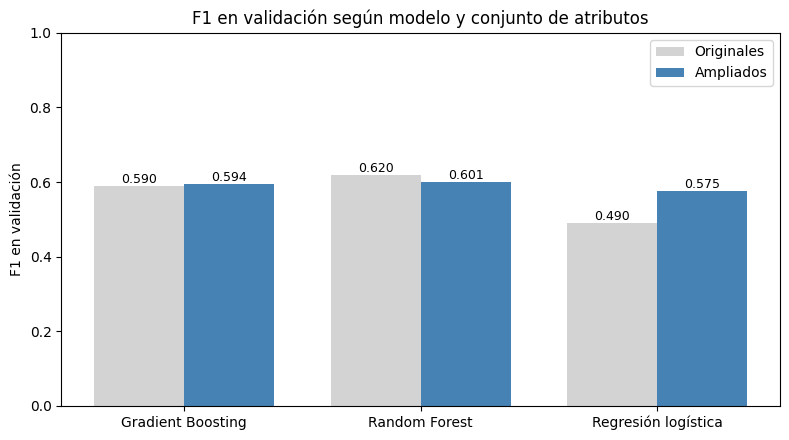

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
posiciones = np.arange(len(comparacion_f1))
ancho = 0.38

barras_orig = ax.bar(posiciones - ancho / 2, comparacion_f1["Originales"], ancho,
                     label="Originales", color="lightgray")
barras_ampl = ax.bar(posiciones + ancho / 2, comparacion_f1["Ampliados"], ancho,
                     label="Ampliados", color="steelblue")

for barras in [barras_orig, barras_ampl]:
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
                f"{barra.get_height():.3f}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(posiciones)
ax.set_xticklabels(comparacion_f1.index)
ax.set_ylabel("F1 en validación")
ax.set_ylim(0, 1)
ax.set_title("F1 en validación según modelo y conjunto de atributos")
ax.legend()
plt.tight_layout()
plt.show()

**Efecto de la ingeniería de características**

* **Regresión logística.** El F1 de validación sube de 0,490 a 0,575, una mejora de casi 9 puntos (cerca de 18% relativo). Es el modelo que más se beneficia.
* **Random Forest y Gradient Boosting.** El cambio es pequeño. El Random Forest baja unos 2 puntos y el Gradient Boosting prácticamente no cambia. Para ellos las variables derivadas son redundantes, y agregar variables redundantes puede incluso introducir algo de ruido.

**Conclusión preliminar.** La ingeniería de características es valiosa para el modelo lineal, pero no aporta a los ensambles basados en árboles. Incluso con las variables nuevas, la regresión logística sigue por debajo de los ensambles.

#### Revisión de sobreajuste

Antes de elegir, revisamos si algún modelo está **sobreajustado**. Para eso comparamos su F1 en tres conjuntos:
* **Entrenamiento.** Los datos con los que se ajustó el modelo.
* **Validación cruzada.** El promedio de las 5 particiones durante la búsqueda de hiperparámetros.
* **Validación.** Datos que el modelo nunca vio.

Si el F1 de entrenamiento es mucho mayor que el de validación, el modelo memorizó los datos de entrenamiento.

In [13]:
f1_entrenamiento = []
for modelos, atributos in [(modelos_originales, ATRIBUTOS_ORIGINALES),
                           (modelos_ampliados, ATRIBUTOS_AMPLIADOS)]:
    for nombre, modelo in modelos.items():
        f1_entrenamiento.append(f1_score(y_train, modelo.predict(X_train[atributos])))

resultados["f1_entrenamiento"] = f1_entrenamiento
resultados["brecha_entren_val"] = resultados["f1_entrenamiento"] - resultados["f1_val"]

resultados[["modelo", "atributos", "f1_entrenamiento", "f1_validacion_cruzada",
            "f1_val", "brecha_entren_val"]].sort_values("f1_val", ascending=False)

,modelo,atributos,f1_entrenamiento,f1_validacion_cruzada,f1_val,brecha_entren_val
1,Random Forest,Originales,0.856,0.620,0.620,0.236
4,Random Forest,Ampliados,0.833,0.616,0.601,0.231
5,Gradient Boosting,Ampliados,0.692,0.605,0.594,0.099
2,Gradient Boosting,Originales,0.682,0.604,0.590,0.092
3,Regresión logística,Ampliados,0.564,0.561,0.575,-0.011
0,Regresión logística,Originales,0.495,0.495,0.490,0.006


La revisión muestra comportamientos distintos:
* **Random Forest.** Tiene la mayor brecha entre entrenamiento y validación (cerca de 0,86 frente a 0,62 con atributos originales). Lo importante es que el F1 de validación cruzada y el de validación coinciden (0,62 en ambos), lo que indica que su desempeño con datos nuevos está bien estimado.
* **Gradient Boosting.** Tiene una brecha menor (alrededor de 0,09). Aprende patrones más generales, aunque con un F1 de validación algo menor.
* **Regresión logística.** Prácticamente no hay brecha. Su limitación no es el sobreajuste sino lo contrario. No tiene la flexibilidad suficiente para capturar todos los patrones.

#### Selección de los candidatos

El criterio de selección es el **mayor F1 en validación**. Lo aplicamos en las dos comparaciones del experimento:

| Comparación | Modelos | F1 validación | Elegido |
|---|---|---|---|
| Ingeniería de características | Regresión logística original frente a ampliada | 0,490 frente a 0,575 | Regresión logística ampliada |
| Tipo de modelo (ensambles) | Random Forest frente a Gradient Boosting, atributos originales | 0,620 frente a 0,590 | Random Forest |
| Tipo de modelo (básico frente a ensamble) | Regresión logística ampliada frente a Random Forest original | 0,575 frente a 0,620 | Random Forest |

**El modelo elegido de forma preliminar es el Random Forest con atributos originales.**

Estas diferencias se observaron en un solo conjunto de validación de 2.000 clientes, y parte de ellas podría deberse al azar de qué clientes quedaron en ese conjunto. Por eso, en el punto 3 compararemos estos pares de modelos sobre el conjunto de **prueba** con pruebas estadísticas pareadas, para confirmar si las diferencias son significativas y relevantes antes de tomar la decisión final.

Guardamos los cuatro modelos que participan en las comparaciones, cada uno con su conjunto de atributos.

In [14]:
CANDIDATOS = {
    "RL originales": (modelos_originales["Regresión logística"], ATRIBUTOS_ORIGINALES),
    "RL ampliados": (modelos_ampliados["Regresión logística"], ATRIBUTOS_AMPLIADOS),
    "RF originales": (modelos_originales["Random Forest"], ATRIBUTOS_ORIGINALES),
    "GB originales": (modelos_originales["Gradient Boosting"], ATRIBUTOS_ORIGINALES),
}

for nombre, (modelo, atributos) in CANDIDATOS.items():
    f1_validacion = f1_score(y_val, modelo.predict(X_val[atributos]))
    print(f"{nombre}: {len(atributos)} atributos, F1 en validación = {f1_validacion:.3f}")

RL originales: 13 atributos, F1 en validación = 0.490
RL ampliados: 18 atributos, F1 en validación = 0.575
RF originales: 13 atributos, F1 en validación = 0.620
GB originales: 13 atributos, F1 en validación = 0.590


## 3. Análisis cuantitativo de resultados

En esta sección evaluamos los modelos candidatos sobre el conjunto de **prueba**, que hasta ahora no se ha usado en ninguna decisión. El objetivo es doble:
1. Medir el desempeño de cada modelo con datos completamente nuevos.
2. Comprobar con pruebas estadísticas si las diferencias que vimos en validación son reales o pueden deberse al azar, y con eso tomar la decisión final.

Comparamos los cuatro candidatos guardados al final del punto 2:

| Nombre | Modelo | Atributos |
|---|---|---|
| RL originales | Regresión logística | 13 originales |
| RL ampliados | Regresión logística | 18 ampliados |
| RF originales | Random Forest | 13 originales |
| GB originales | Gradient Boosting | 13 originales |

### 3.1 Métricas en el conjunto de prueba

Calculamos las predicciones de cada candidato sobre los 2.000 clientes de prueba. Guardamos dos tipos de predicción:
* La **clase predicha** (0 o 1), que usa el umbral por defecto de 0,5. Si la probabilidad estimada de churn es mayor a 0,5, el modelo predice que el cliente abandona.
* La **probabilidad de churn**, que permite calcular métricas que no dependen de un umbral.

In [15]:
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score

y_prueba = np.asarray(y_test)

predicciones = {}
probabilidades = {}
for nombre, (modelo, atributos) in CANDIDATOS.items():
    predicciones[nombre] = modelo.predict(X_test[atributos])
    probabilidades[nombre] = modelo.predict_proba(X_test[atributos])[:, 1]

Calculamos seis métricas para cada candidato. En el contexto del banco, un **positivo** es un cliente que el modelo señala como "en riesgo de abandonar", y por lo tanto un cliente al que se contactaría con la campaña de retención.

| Métrica | Pregunta que responde para el banco |
|---|---|
| **Exactitud** | ¿Qué porcentaje de los clientes clasificó bien el modelo? Es engañosa con clases desbalanceadas |
| **Precisión** | De los clientes que contactamos, ¿qué porcentaje realmente se iba a ir? Una precisión baja significa gastar la campaña en clientes que se iban a quedar de todas formas |
| **Recall** | De los clientes que realmente se iban a ir, ¿qué porcentaje detectamos? Un recall bajo significa perder clientes que pudimos intentar retener |
| **F1** | Media armónica de precisión y recall. Solo es alta si ambas lo son |
| **ROC-AUC** | Probabilidad de que el modelo le asigne más riesgo a un cliente que se va que a uno que se queda, elegidos al azar. No depende del umbral |
| **PR-AUC** | Resume la precisión que se obtiene en todos los niveles de recall posibles. No depende del umbral y, con clases desbalanceadas, es más exigente que ROC-AUC. |

Como referencia, un modelo que siempre dijera "este cliente no se va" tendría una exactitud cercana al 80% (la proporción de clientes que no abandona), pero una precisión, un recall y un F1 de 0, porque no detectaría a ningún cliente en riesgo.

In [16]:
metricas_prueba = pd.DataFrame({
    nombre: {
        "Exactitud": accuracy_score(y_prueba, predicciones[nombre]),
        "Precisión": precision_score(y_prueba, predicciones[nombre]),
        "Recall": recall_score(y_prueba, predicciones[nombre]),
        "F1": f1_score(y_prueba, predicciones[nombre]),
        "ROC-AUC": roc_auc_score(y_prueba, probabilidades[nombre]),
        "PR-AUC": average_precision_score(y_prueba, probabilidades[nombre]),
    }
    for nombre in CANDIDATOS
}).T

metricas_prueba

,Exactitud,Precisión,Recall,F1,ROC-AUC,PR-AUC
RL originales,0.710,0.381,0.686,0.490,0.763,0.449
RL ampliados,0.778,0.471,0.730,0.573,0.842,0.657
RF originales,0.861,0.680,0.600,0.637,0.868,0.712
GB originales,0.799,0.504,0.742,0.600,0.867,0.711


**Interpretación de las métricas en prueba**

* **Random Forest** tiene el mejor F1 (0,637), la mejor exactitud (0,861) y, sobre todo, la mejor **precisión** (0,680). De cada 10 clientes que señala como en riesgo, casi 7 realmente iban a abandonar. Su recall es de 0,600, es decir, detecta 6 de cada 10 clientes que se van.
* **Gradient Boosting** tiene el comportamiento opuesto, con el mejor **recall** (0,742) pero una precisión de 0,504. Detecta más clientes en riesgo, pero la mitad de los clientes que señala se iba a quedar de todas formas.
* **Regresión logística ampliada** queda por debajo de los dos ensambles en F1 (0,573), pero supera claramente a la logística original (0,490), que es el peor modelo en todas las métricas.

**Los dos ensambles ordenan a los clientes igual de bien.** Su ROC-AUC (0,868 y 0,867) y su PR-AUC (0,712 y 0,711) son muy parecidos. Estas métricas al o depender del umbral miden qué tan bien el modelo ordena a los clientes de mayor a menor riesgo. La diferencia en F1, precisión y recall viene principalmente del punto de corte. Con el umbral de 0,5, el Gradient Boosting marca a muchos más clientes como positivos que el Random Forest. Esto significa que **la elección entre ambos depende de cuánto le cuesta al banco un falso positivo frente a un falso negativo.**

Todos los modelos superan con amplitud al azar. Un modelo sin capacidad predictiva tendría un PR-AUC cercano a 0,20 (la tasa de churn), y los ensambles llegan a 0,71.


#### Matriz de confusión 

| | Predice "se queda" | Predice "se va" |
|---|---|---|
| **Realmente se queda** | Verdadero negativo. No se contacta, correcto | Falso positivo. Se contacta sin necesidad (costo de campaña desperdiciado) |
| **Realmente se va** | Falso negativo. No se contacta y se pierde el cliente | Verdadero positivo. Se contacta y existe la oportunidad de retenerlo |

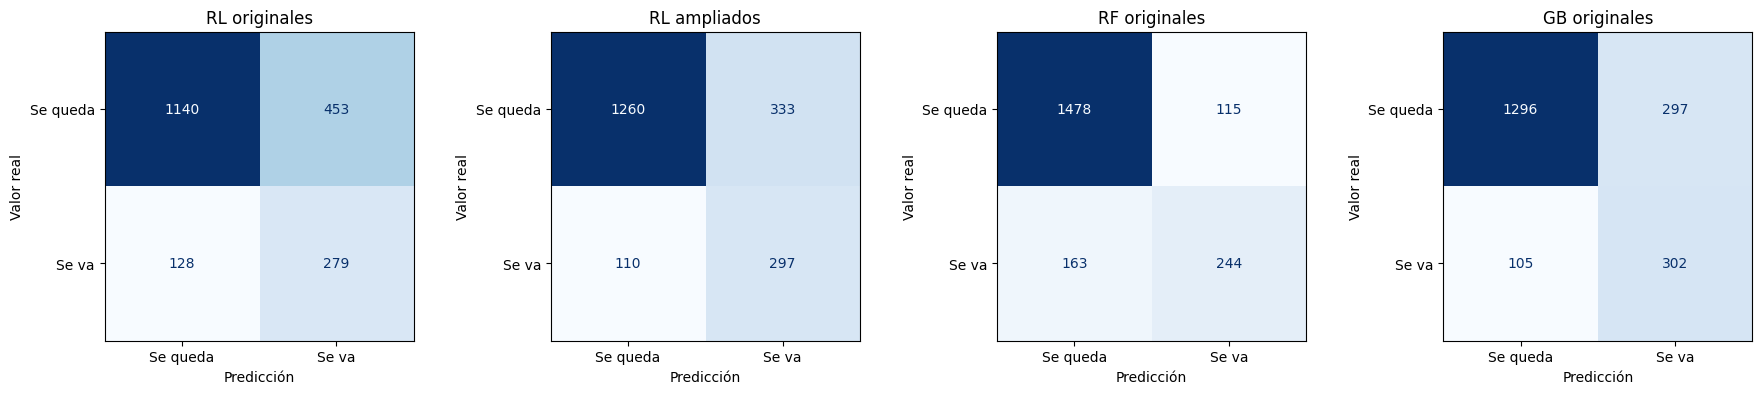

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, nombre in zip(axes, CANDIDATOS):
    ConfusionMatrixDisplay.from_predictions(
        y_prueba, predicciones[nombre], display_labels=["Se queda", "Se va"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nombre)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
plt.tight_layout()
plt.show()

En el conjunto de prueba hay 407 clientes que abandonaron. Las matrices muestran cómo cada modelo distribuye sus aciertos y errores:
* El **Random Forest** detecta 244 de esos 407 clientes y señala en total a 359 clientes, de los cuales 115 son falsas alarmas.
* El **Gradient Boosting** detecta 302 de los 407, pero para lograrlo señala a 599 clientes, con 297 falsas alarmas.

Es decir, para detectar 58 clientes adicionales que se iban a ir, el Gradient Boosting contacta a 240 clientes más. Si eso conviene o no depende del costo de contactar a un cliente frente al valor de retenerlo, que se calcula en el punto 5.

### 3.2 Intervalos de confianza por bootstrapping

Las métricas anteriores se calcularon con una sola muestra de 2.000 clientes. Si el banco tuviera otros 2.000 clientes, los valores serían un poco distintos. Para cuantificar esa incertidumbre usamos **bootstrapping**:
1. Tomamos una muestra de 2.000 clientes del conjunto de prueba **con reemplazo** (un mismo cliente puede aparecer varias veces y otros no aparecer).
2. Calculamos las métricas de cada modelo sobre esa muestra.
3. Repetimos el proceso 1.000 veces (`B = 1000`), con semilla 42.
4. El intervalo de confianza del 95% de cada métrica va del percentil 2,5 al percentil 97,5 de sus 1.000 valores.

En cada réplica usamos **la misma muestra de clientes para los cuatro modelos**. Así, las réplicas sirven también para comparar los modelos de forma pareada, porque en cada réplica todos los modelos se evalúan sobre exactamente los mismos clientes.

In [18]:
B = 1000
rng = np.random.default_rng(SEED)
n_prueba = len(y_prueba)

METRICAS_BOOTSTRAP = {
    "F1": lambda y, p: f1_score(y, p, zero_division=0),
    "Precisión": lambda y, p: precision_score(y, p, zero_division=0),
    "Recall": lambda y, p: recall_score(y, p, zero_division=0),
    "Exactitud": accuracy_score,
}

replicas = {nombre: {metrica: np.empty(B) for metrica in METRICAS_BOOTSTRAP} for nombre in CANDIDATOS}

for b in range(B):
    idx = rng.integers(0, n_prueba, n_prueba)
    for nombre in CANDIDATOS:
        for metrica, funcion in METRICAS_BOOTSTRAP.items():
            replicas[nombre][metrica][b] = funcion(y_prueba[idx], predicciones[nombre][idx])

filas = []
for nombre in CANDIDATOS:
    for metrica in METRICAS_BOOTSTRAP:
        inferior, superior = np.percentile(replicas[nombre][metrica], [2.5, 97.5])
        filas.append({"modelo": nombre, "métrica": metrica,
                      "observado": metricas_prueba.loc[nombre, metrica],
                      "IC 2,5%": inferior, "IC 97,5%": superior})

intervalos = pd.DataFrame(filas)
intervalos.pivot(index="modelo", columns="métrica", values=["observado", "IC 2,5%", "IC 97,5%"]).round(3)

observado                          IC 2,5%                  \
métrica       Exactitud    F1 Precisión Recall Exactitud    F1 Precisión   
modelo                                                                     
GB originales     0.799 0.600     0.504  0.742     0.780 0.559     0.459   
RF originales     0.861 0.637     0.680  0.600     0.845 0.594     0.627   
RL ampliados      0.778 0.573     0.471  0.730     0.760 0.537     0.432   
RL originales     0.710 0.490     0.381  0.686     0.688 0.452     0.344   

                      IC 97,5%                         
métrica       Recall Exactitud    F1 Precisión Recall  
modelo                                                 
GB originales  0.699     0.817 0.635     0.542  0.784  
RF originales  0.550     0.878 0.676     0.724  0.647  
RL ampliados   0.689     0.796 0.605     0.506  0.773  
RL originales  0.638     0.728 0.520     0.412  0.729

Graficamos el F1 de cada modelo con su intervalo de confianza como barra de error. Si los intervalos de dos modelos no se superponen, hay evidencia fuerte de que son distintos. Si se superponen, **no** se puede concluir que sean iguales. La superposición de intervalos es un criterio conservador, y la forma correcta de comparar dos modelos es calcular el intervalo de su **diferencia**, que hacemos en la sección 3.3.

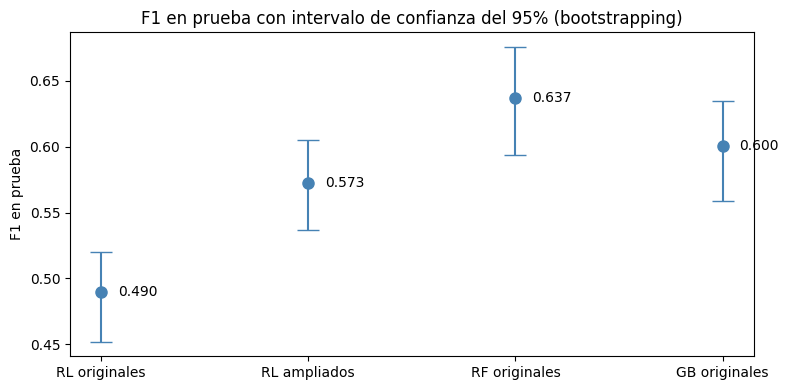

In [19]:
f1_intervalos = intervalos[intervalos["métrica"] == "F1"].set_index("modelo")
errores = [f1_intervalos["observado"] - f1_intervalos["IC 2,5%"],
           f1_intervalos["IC 97,5%"] - f1_intervalos["observado"]]

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(f1_intervalos.index, f1_intervalos["observado"], yerr=errores,
            fmt="o", color="steelblue", capsize=8, markersize=8)
for i, (nombre, fila) in enumerate(f1_intervalos.iterrows()):
    ax.text(i + 0.08, fila["observado"], f"{fila['observado']:.3f}", va="center")
ax.set_ylabel("F1 en prueba")
ax.set_title("F1 en prueba con intervalo de confianza del 95% (bootstrapping)")
plt.tight_layout()
plt.show()

Los intervalos tienen un ancho de aproximadamente ±0,04 en F1. Esto indica que, con 2.000 clientes de prueba, el F1 de cada modelo está estimado con una precisión de unos 4 puntos hacia arriba o hacia abajo. Si el conjunto de prueba tuviera el doble de clientes, los intervalos serían más estrechos.

El intervalo de la regresión logística original (0,45 a 0,52) no se superpone con el de ningún otro modelo, por lo que es claramente el peor. Los intervalos del Random Forest (0,59 a 0,68), el Gradient Boosting (0,56 a 0,64) y la logística ampliada (0,54 a 0,61) sí se superponen entre sí. Como explicamos arriba, esto no significa que sean equivalentes. Para compararlos correctamente necesitamos el intervalo de la diferencia, que calculamos a continuación.

### 3.3 Prueba A/B pareada por bootstrapping

Comparamos los modelos de dos en dos. Las comparaciones siguen las dos preguntas del punto 2:

| Pregunta | Modelo A | Modelo B |
|---|---|---|
| ¿La ingeniería de características mejora el modelo? | RL ampliados | RL originales |
| ¿Qué ensamble es mejor? | RF originales | GB originales |
| ¿Un ensamble supera al mejor modelo básico? | RF originales | RL ampliados |

**¿Por qué una prueba pareada?** Los dos modelos de cada comparación predicen sobre **los mismos clientes**. Algunos clientes son fáciles de clasificar y otros difíciles, y eso afecta a los dos modelos por igual. Al comparar las métricas sobre la misma muestra de clientes en cada réplica, esa variación común se cancela, y el intervalo de la diferencia es más estrecho y más preciso que si tratáramos a los modelos como grupos independientes.

**Procedimiento**:
1. En cada una de las 1.000 réplicas de la sección 3.2 calculamos la diferencia de cada métrica entre el modelo A y el B, `d = métrica(A) - métrica(B)`.
2. El **intervalo de confianza del 95%** de la diferencia va del percentil 2,5 al 97,5 de esas 1.000 diferencias.
3. El **valor p por bootstrapping** se calcula como `p = 2 · min(proporción de d ≤ 0, proporción de d ≥ 0)`. Siempre coincide con el intervalo, porque p < 0,05 exactamente cuando el 0 queda fuera del intervalo.

**Regla de decisión.** La diferencia es **significativa** si el intervalo excluye el 0. Para concluir que un modelo es mejor, además debe ser **relevante**. La diferencia debe superar un umbral con importancia práctica. Usamos un umbral de **0,02** (2 puntos), el mismo valor que usa la practica del curso. Una diferencia menor, aunque fuera significativa, no justificaría preferir un modelo sobre otro.

In [20]:
UMBRAL_RELEVANTE = 0.02

COMPARACIONES = [
    ("Ingeniería de características", "RL ampliados", "RL originales"),
    ("Ensambles", "RF originales", "GB originales"),
    ("Básico frente a ensamble", "RF originales", "RL ampliados"),
]

diferencias = {}
filas = []
for pregunta, modelo_a, modelo_b in COMPARACIONES:
    for metrica in METRICAS_BOOTSTRAP:
        d = replicas[modelo_a][metrica] - replicas[modelo_b][metrica]
        diferencias[(pregunta, metrica)] = d
        inferior, superior = np.percentile(d, [2.5, 97.5])
        p_boot = min(1.0, 2 * min(np.mean(d <= 0), np.mean(d >= 0)))
        filas.append({
            "comparación": f"{modelo_a} - {modelo_b}",
            "métrica": metrica,
            "diferencia": metricas_prueba.loc[modelo_a, metrica] - metricas_prueba.loc[modelo_b, metrica],
            "IC 2,5%": inferior,
            "IC 97,5%": superior,
            "p bootstrapping": p_boot,
        })

ab_pareada = pd.DataFrame(filas)
ab_pareada["significativa"] = (ab_pareada["IC 2,5%"] > 0) | (ab_pareada["IC 97,5%"] < 0)
ab_pareada["relevante"] = ab_pareada["significativa"] & (ab_pareada["diferencia"].abs() >= UMBRAL_RELEVANTE)
ab_pareada.round(4)

,comparación,métrica,diferencia,"IC 2,5%","IC 97,5%",p bootstrapping,significativa,relevante
0,RL ampliados - RL originales,F1,0.083,0.057,0.112,0.000,True,True
1,RL ampliados - RL originales,Precisión,0.090,0.066,0.116,0.000,True,True
2,RL ampliados - RL originales,Recall,0.044,0.005,0.089,0.032,True,True
3,RL ampliados - RL originales,Exactitud,0.069,0.051,0.088,0.000,True,True
4,RF originales - GB originales,F1,0.037,0.005,0.067,0.026,True,True
5,RF originales - GB originales,Precisión,0.175,0.142,0.210,0.000,True,True
6,RF originales - GB originales,Recall,-0.142,-0.182,-0.105,0.000,True,True
7,RF originales - GB originales,Exactitud,0.062,0.047,0.076,0.000,True,True
8,RF originales - RL ampliados,F1,0.064,0.030,0.096,0.000,True,True
9,RF originales - RL ampliados,Precisión,0.208,0.170,0.244,0.000,True,True


Graficamos la distribución de las 1.000 diferencias de F1 de cada comparación. La línea negra marca el 0 (ninguna diferencia), las líneas grises punteadas marcan el umbral relevante de ±0,02 y la zona sombreada es el intervalo de confianza del 95%. Si la zona sombreada no toca la línea negra, la diferencia es significativa.

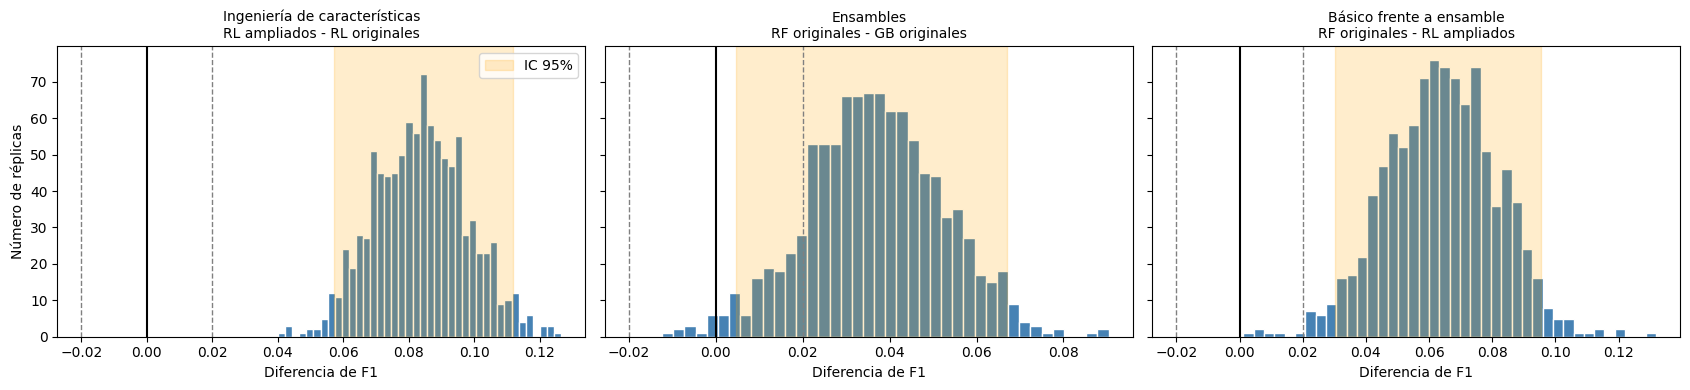

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, (pregunta, modelo_a, modelo_b) in zip(axes, COMPARACIONES):
    d = diferencias[(pregunta, "F1")]
    inferior, superior = np.percentile(d, [2.5, 97.5])
    ax.hist(d, bins=40, color="steelblue", edgecolor="white")
    ax.axvspan(inferior, superior, color="orange", alpha=0.2, label="IC 95%")
    ax.axvline(0, color="black", linewidth=1.5)
    for limite in [-UMBRAL_RELEVANTE, UMBRAL_RELEVANTE]:
        ax.axvline(limite, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{pregunta}\n{modelo_a} - {modelo_b}", fontsize=10)
    ax.set_xlabel("Diferencia de F1")
axes[0].set_ylabel("Número de réplicas")
axes[0].legend()
plt.tight_layout()
plt.show()

**Interpretación de la prueba A/B pareada**

* **Ingeniería de características (RL ampliados frente a RL originales).** El F1 mejora en 0,083, con intervalo de 0,057 a 0,112 que excluye el 0 y está completamente por encima del umbral de 0,02. La mejora es **significativa y relevante**, y aparece también en precisión, recall y exactitud. Las variables derivadas mejoran la regresión logística.
* **Ensambles (RF frente a GB).** El F1 del Random Forest es mayor en 0,037, con intervalo de 0,005 a 0,067 y valor p de 0,026. La diferencia es significativa y la diferencia observada supera el umbral, por lo que se cumple la regla de decisión. Sin embargo, la evidencia es más débil que en las otras comparaciones. En precisión y recall las diferencias son grandes y van en **sentidos opuestos**. El Random Forest tiene 0,175 más de precisión y 0,142 menos de recall.
* **Básico frente a ensamble (RF frente a RL ampliados).** El Random Forest supera a la logística ampliada en F1 por 0,064, con intervalo de 0,030 a 0,096. La diferencia es significativa y relevante. Al igual que contra el Gradient Boosting, el Random Forest gana en precisión y exactitud y pierde en recall.

Los histogramas muestran lo mismo. En las tres comparaciones la zona del intervalo no toca la línea del 0. En la comparación entre ensambles el intervalo queda más cerca del 0, lo que refleja que la diferencia a pesar de ser significativa, no es tan grande.

### 3.4 Prueba de McNemar

La prueba de McNemar compara dos modelos a partir de una **tabla de contingencia** de sus aciertos sobre los mismos clientes:

| | B acierta | B se equivoca |
|---|---|---|
| **A acierta** | Ambos aciertan | Solo A acierta |
| **A se equivoca** | Solo B acierta | Ambos se equivocan |

Solo importan las celdas de **desacuerdo** ("solo A acierta" y "solo B acierta"). Los clientes en los que ambos aciertan o ambos fallan no dicen nada sobre cuál es mejor. La hipótesis nula es que los dos modelos se equivocan con la misma frecuencia y que la diferencia entre esas dos celdas se debe al azar.

Aplicamos la prueba dos veces:
* **Con todos los clientes de prueba.** Compara la **exactitud** de los modelos.
* **Solo con los clientes que abandonaron (`churn = 1`).** Compara el **recall**, porque en esos clientes acertar significa detectarlos.

In [23]:
from statsmodels.stats.contingency_tables import mcnemar


def prueba_mcnemar(pred_a, pred_b, y_real):
    """Construye la tabla de aciertos de dos modelos y aplica la prueba de McNemar."""
    acierta_a = pred_a == y_real
    acierta_b = pred_b == y_real
    tabla = pd.crosstab(acierta_a, acierta_b).reindex(index=[True, False], columns=[True, False], fill_value=0)
    solo_a = tabla.loc[True, False]
    solo_b = tabla.loc[False, True]
    resultado = mcnemar(tabla.to_numpy(), exact=(solo_a + solo_b) < 25, correction=True)
    return solo_a, solo_b, resultado.statistic, resultado.pvalue


filas = []
for pregunta, modelo_a, modelo_b in COMPARACIONES:
    for grupo, mascara in [("Todos (exactitud)", np.ones(n_prueba, dtype=bool)),
                           ("Churn = 1 (recall)", clientes_churn)]:
        solo_a, solo_b, estadistico, p_valor = prueba_mcnemar(
            predicciones[modelo_a][mascara], predicciones[modelo_b][mascara], y_prueba[mascara])
        filas.append({"comparación": f"{modelo_a} - {modelo_b}", "clientes": grupo,
                      "solo A acierta": solo_a, "solo B acierta": solo_b,
                      "estadístico": estadistico, "valor p": p_valor})

resultados_mcnemar = pd.DataFrame(filas)
resultados_mcnemar["significativa"] = resultados_mcnemar["valor p"] < 0.05
resultados_mcnemar.round(4)

,comparación,clientes,solo A acierta,solo B acierta,estadístico,valor p,significativa
0,RL ampliados - RL originales,Todos (exactitud),246,108,53.020,0.000,True
1,RL ampliados - RL originales,Churn = 1 (recall),48,30,3.705,0.054,False
2,RF originales - GB originales,Todos (exactitud),186,62,61.004,0.000,True
3,RF originales - GB originales,Churn = 1 (recall),3,61,50.766,0.000,True
4,RF originales - RL ampliados,Todos (exactitud),248,83,81.257,0.000,True
5,RF originales - RL ampliados,Churn = 1 (recall),12,65,35.117,0.000,True


**Interpretación de la prueba de McNemar**

* **Con todos los clientes (exactitud).** En las tres comparaciones un modelo acierta en muchos más clientes exclusivos que el otro. Por ejemplo, hay 186 clientes en los que solo acierta el Random Forest y 62 en los que solo acierta el Gradient Boosting. Las tres diferencias son significativas.
* **Solo con los clientes que abandonaron (recall).** El Gradient Boosting detecta 61 clientes que el Random Forest no detecta, mientras que el Random Forest detecta solo 3 que el Gradient Boosting no detecta. Algo parecido ocurre con la logística ampliada frente al Random Forest (65 frente a 12). Esto confirma que el Random Forest es el modelo más conservador al señalar clientes en riesgo.
* **Recall en la ingeniería de características.** McNemar da un valor p de 0,054, justo por encima de 0,05, mientras que el bootstrapping 0,032. La conclusión prudente es que la ingeniería de características mejora claramente la precisión y la exactitud de la logística, y que su efecto sobre el recall es pequeño.

### 3.6 Conclusiones y elección del modelo

**Resumen de las pruebas.** Cada celda indica si la diferencia es significativa (S) o no (NS) y, para las pruebas de bootstrapping, si además es relevante (umbral de 0,02). La prueba McNemar compara exactitud (con todos los clientes) y recall (solo con los que abandonaron).

| Comparación | Métrica | A/B pareada (bootstrapping) | McNemar | Ganador |
|---|---|---|---|---|
| RL ampliados frente a RL originales | F1 | S, relevante | No aplica | RL ampliados |
| | Precisión | S, relevante | No aplica | RL ampliados |
| | Recall | S, relevante | NS (p = 0,054) | RL ampliados, evidencia débil |
| | Exactitud | S, relevante | S | RL ampliados |
| RF frente a GB | F1 | S, relevante (evidencia débil) | No aplica | RF |
| | Precisión | S, relevante | No aplica | RF |
| | Recall | S, relevante | S | GB |
| | Exactitud | S, relevante | S | RF |
| RF frente a RL ampliados | F1 | S, relevante | No aplica | RF |
| | Precisión | S, relevante | No aplica | RF |
| | Recall | S, relevante | S | RL ampliados |
| | Exactitud | S, relevante | S | RF |

**¿Qué tuvo un efecto más claro, la ingeniería de características o el tipo de modelo?** Ambos tuvieron efectos significativos y relevantes, pero de distinta naturaleza. La ingeniería de características mejoró a la regresión logística en todas las métricas, mientras que en validación no aportó nada a los ensambles. El cambio de tipo de modelo produjo la mayor ganancia total. El Random Forest con las variables originales supera a la mejor logística en 6 puntos de F1, sin necesidad de crear variables nuevas.

**Modelo elegido en este punto: Random Forest con atributos originales.** Las razones son:
1. Tiene el mayor F1 en validación y en prueba, y su ventaja sobre los demás candidatos es significativa y supera el umbral relevante.
2. Tiene la mayor precisión y exactitud. Para una campaña de retención en la que se paga por cada cliente contactado, una precisión alta significa menos dinero gastado en clientes que no se iban a ir.
3. Ordena a los clientes por riesgo tan bien como el Gradient Boosting (mismos ROC-AUC y PR-AUC).
4. Usa solo las 13 variables originales, sin variables derivadas que haya que construir y mantener.

**A tener en cuenta** La principal debilidad del Random Forest es su recall. Con el umbral de 0,5 deja pasar 4 de cada 10 clientes que abandonan. Si el banco valorara más no perder clientes que ahorrar en contactos, el Gradient Boosting sería preferible con el umbral actual. Sin embargo, como los dos ensambles ordenan a los clientes igual de bien, el Random Forest puede alcanzar un recall mayor simplemente bajando su umbral de decisión. Por eso la elección del umbral, basada en los costos y beneficios de la campaña, es algo que puede hacer que el gradient boosting sea preferible.

#### ¿Qué impactó positivamente las métricas?

1. **La flexibilidad de los modelos de ensamble.** Las relaciones más fuertes con el churn no son monótonas (número de productos y edad) y hay interacciones entre variables (país y saldo). Los árboles las capturan por sí solos, mientras que la regresión logística no puede.
2. **El balanceo de clases.** Los tres modelos eligieron `class_weight` balanceado en la validación cruzada. Sin él, los modelos tienden a predecir casi siempre "no abandona" y su recall cae.
3. **La ingeniería de características para el modelo lineal.** Las variables `productos_1` y `productos_3mas` le dieron a la regresión logística una forma de representar la relación no monótona de los productos, y su F1 subió 8 puntos.
4. **La búsqueda amplia de hiperparámetros.** Ampliar el espacio de búsqueda permitió al Random Forest elegir hojas de al menos 5 clientes, lo que redujo la memorización de los datos de entrenamiento y mejoró su F1 en validación.
5. **La limpieza de los datos.** Eliminar duplicados evitó que clientes repetidos quedaran a la vez en entrenamiento y en prueba, lo que habría inflado las métricas de forma artificial.

#### Oportunidades de mejora

1. **Ajustar el umbral de decisión** según los costos del negocio, en lugar de usar 0,5. Esta es la mejora con mayor impacto esperado y no requiere entrenar de nuevo el modelo.
2. **Incorporar variables de comportamiento.** El dataset solo describe el perfil del cliente en un momento. Variables como la evolución del saldo en los últimos meses, la frecuencia de uso de los productos o las quejas presentadas podrían anticipar mejor el abandono.
3. **Validar con datos colombianos.** El modelo se entrenó con clientes europeos con una tasa de churn del 20%. Antes de usarlo en un banco colombiano (con una tasa cercana al 15%), habría que evaluarlo, y probablemente reentrenarlo, con datos locales.
4. **Calibrar las probabilidades.** Con `class_weight` balanceado, las probabilidades que entrega el modelo no corresponden a la probabilidad real de abandono. Calibrarlas permitiría usarlas directamente en el cálculo del valor esperado de cada contacto.
5. **Reducir variables poco informativas.** El salario estimado y la tenencia de tarjeta de crédito mostraron una relación casi nula con el churn. Retirarlas podría simplificar el modelo sin perder desempeño, lo que se puede evaluar con el análisis de importancia del punto 4.

## 4. Análisis cualitativo de resultados

En esta sección buscamos entender cómo toma sus decisiones el modelo elegido (Random Forest con atributos originales). Un Random Forest combina 500 árboles, así que no se puede leer directamente como una regresión logística. Por eso usamos tres técnicas de interpretación, siguiendo la Práctica 5 del curso:

| Técnica | Alcance | Pregunta que responde |
|---|---|---|
| **ICE y PDP** | Global | ¿Cómo cambia la probabilidad de churn cuando varía una variable, dejando las demás fijas? |
| **SHAP** | Global y local | ¿Cuánto aporta cada variable a cada predicción, y en qué dirección? |
| **LIME** | Local | ¿Qué variables explican la predicción de un cliente en particular, según un modelo lineal aproximado a su alrededor? |

Primero examinamos el **comportamiento global** (secciones 4.1 y 4.2) y luego una **muestra de predicciones individuales** (sección 4.3).


### 4.0 Preparación

Separamos las piezas del pipeline del modelo elegido:
* `modelo_rf`. El pipeline completo (imputación, escalado y Random Forest). Recibe los datos originales y devuelve la probabilidad de churn.
* `preprocesador`. Solo los pasos de imputación y escalado, ya ajustados con el entrenamiento. Se usa `transform` y no `fit`, porque las técnicas de interpretación deben ver los datos exactamente como los vio el modelo, sin volver a aprender nada.
* `bosque`. Solo el Random Forest, que necesita SHAP.

También creamos versiones **imputadas pero sin escalar** de los datos. Los gráficos se leen mucho mejor en las unidades originales (edad en años, saldo en euros) que en valores estandarizados. Como el escalado es una transformación que no cambia el orden de los valores, los árboles toman las mismas decisiones en una u otra escala, y podemos mostrar las unidades originales sin alterar la interpretación.

In [24]:
modelo_rf, atributos_rf = CANDIDATOS["RF originales"]
preprocesador = modelo_rf[:-1]
bosque = modelo_rf.named_steps["modelo"]
imputador = modelo_rf.named_steps["imputador"]


def imputar(X):
    """Imputa los faltantes con las medianas del entrenamiento y conserva las unidades originales."""
    return pd.DataFrame(imputador.transform(X[atributos_rf]), columns=atributos_rf, index=X.index)


X_entrenamiento_imp = imputar(X_train)
X_prueba_imp = imputar(X_test)
prob_rf_prueba = modelo_rf.predict_proba(X_test[atributos_rf])[:, 1]

print(f"Clientes de prueba: {len(X_prueba_imp)}, atributos: {len(atributos_rf)}")

Clientes de prueba: 2000, atributos: 13


### 4.1 Gráficos ICE y PDP (comportamiento global)

Un gráfico **ICE** toma un cliente, cambia el valor de una sola variable a lo largo de su rango (dejando todas las demás iguales) y registra cómo cambia la probabilidad de churn que predice el modelo. Cada línea delgada es un cliente. La línea gruesa es el promedio de todas las líneas, que se conoce como **PDP** (*Partial Dependence Plot*).

* La **forma** de la línea promedio muestra la relación que aprendió el modelo entre la variable y el riesgo.
* Si las líneas individuales son **paralelas**, la variable afecta a todos los clientes por igual. Si se **cruzan o separan**, el efecto depende de otras características del cliente (hay interacciones).

Usamos 200 clientes de prueba elegidos al azar y las tres variables que el EDA mostró como más relacionadas con el churn, que son `age`, `balance` y `products_number`.

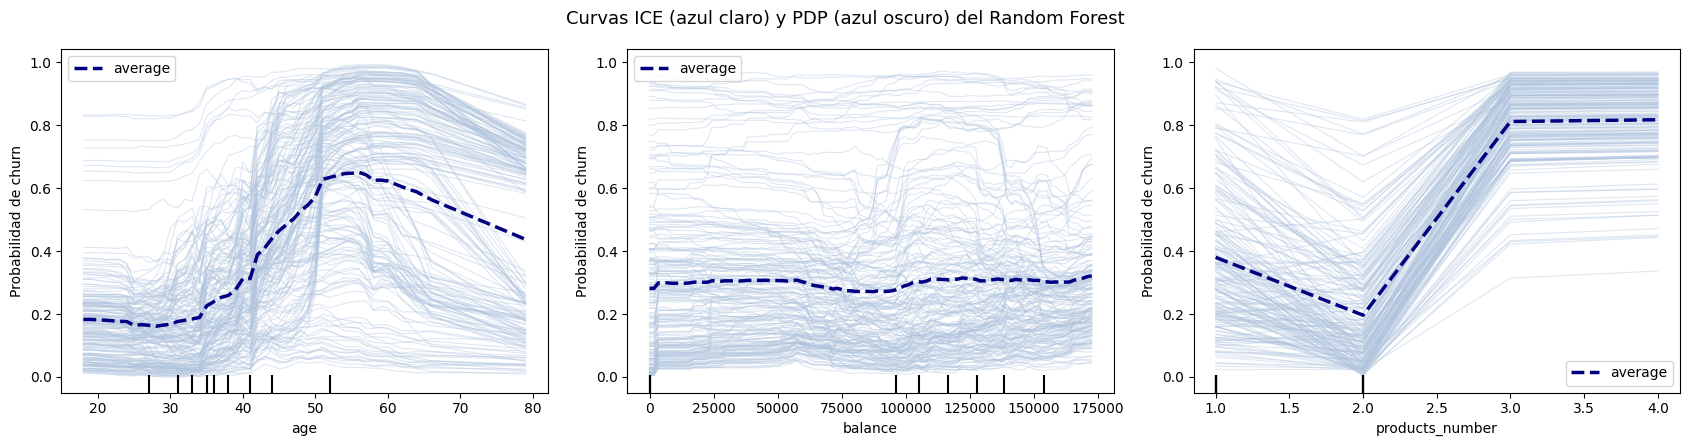

In [25]:
from sklearn.inspection import PartialDependenceDisplay

X_ice = X_prueba_imp.sample(200, random_state=SEED)
variables_ice = ["age", "balance", "products_number"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
PartialDependenceDisplay.from_estimator(
    modelo_rf, X_ice, features=variables_ice, kind="both",
    response_method="predict_proba", random_state=SEED, ax=axes,
    ice_lines_kw={"color": "lightsteelblue", "alpha": 0.4, "linewidth": 0.8},
    pd_line_kw={"color": "navy", "linewidth": 2.5},
)
for ax in fig.axes:
    if ax.get_ylabel():
        ax.set_ylabel("Probabilidad de churn")
fig.suptitle("Curvas ICE (azul claro) y PDP (azul oscuro) del Random Forest", fontsize=13)
plt.tight_layout()
plt.show()

**Interpretación de las curvas ICE y PDP**

* **`age`.** El riesgo promedio se mantiene bajo (cerca de 0,18) hasta los 35 años, sube con fuerza entre los 40 y los 50, alcanza su máximo (cerca de 0,65) entre los 52 y los 57 años, y luego baja. El modelo aprendió la misma relación no monótona que encontramos en el EDA, donde el grupo de 51 a 60 años tenía la mayor tasa de churn. Las curvas individuales no son paralelas. En algunos clientes la edad casi no cambia el riesgo y en otros lo multiplica, lo que indica que el efecto de la edad depende de otras características del cliente.
* **`balance`.** La curva promedio es prácticamente plana, alrededor de 0,30. Solo se ve un pequeño salto al pasar de saldo 0 a un saldo positivo. El saldo, por sí solo, mueve poco la predicción.
* **`products_number`.** La curva tiene forma de U. El riesgo baja de 0,38 con 1 producto a 0,20 con 2 productos, y sube bruscamente a más de 0,80 con 3 o 4 productos. Las curvas individuales son casi paralelas, así que este efecto se aplica de forma parecida a todos los clientes.

Las marcas en el eje horizontal indican los deciles de cada variable en los datos. Las zonas sin marcas (por ejemplo, edades mayores de 60) tienen pocos clientes, por lo que el comportamiento del modelo en esos rangos está basado en menos información.

**Interacción entre edad y actividad.** En el EDA vimos que tanto la edad como ser miembro activo se relacionan con el churn. Para saber si el modelo trata la edad igual en clientes activos e inactivos, repetimos las curvas ICE de la edad coloreando cada cliente según `active_member`, y dibujamos el promedio de cada grupo.

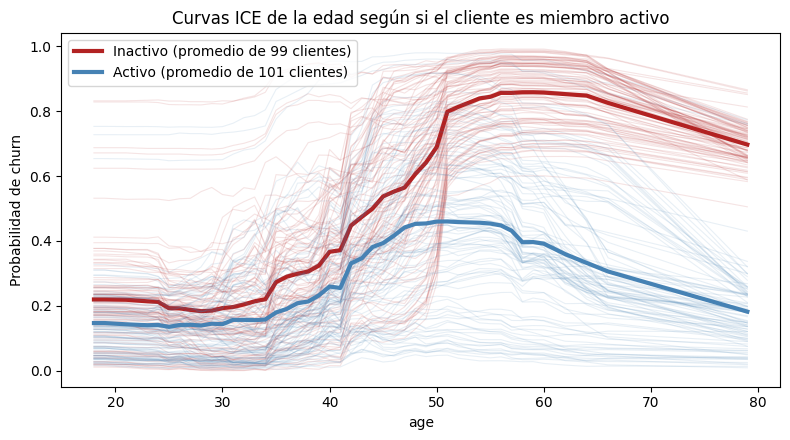

In [26]:
from sklearn.inspection import partial_dependence

ice_edad = partial_dependence(modelo_rf, X_ice, features=["age"], kind="individual",
                              response_method="predict_proba")
grilla_edad = ice_edad["grid_values"][0]
curvas_edad = ice_edad["individual"][0]
es_activo = X_ice["active_member"].to_numpy() == 1

fig, ax = plt.subplots(figsize=(8, 4.5))
for activo, color, etiqueta in [(False, "firebrick", "Inactivo"), (True, "steelblue", "Activo")]:
    curvas = curvas_edad[es_activo == activo]
    ax.plot(grilla_edad, curvas.T, color=color, alpha=0.12, linewidth=0.8)
    ax.plot(grilla_edad, curvas.mean(axis=0), color=color, linewidth=3,
            label=f"{etiqueta} (promedio de {len(curvas)} clientes)")
ax.set_xlabel("age")
ax.set_ylabel("Probabilidad de churn")
ax.set_title("Curvas ICE de la edad según si el cliente es miembro activo")
ax.legend()
plt.tight_layout()
plt.show()

El gráfico revela una **interacción** clara entre la edad y la actividad del cliente:
* Hasta los 40 años, activos e inactivos tienen un riesgo bajo y parecido.
* A partir de los 40, el riesgo de los **inactivos** sube mucho más rápido y alcanza cerca de 0,86 entre los 55 y los 65 años.
* El riesgo de los **activos** sube menos (máximo cercano a 0,46) y, después de los 60 años, vuelve a bajar hasta 0,18.

Para el modelo la edad es un factor de riesgo importante sobre todo en los clientes inactivos. Un cliente mayor que usa activamente el banco es poco probable que se vaya, mientras que un cliente mayor e inactivo es el perfil de mayor riesgo. Esta interacción es la que un modelo lineal no puede capturar sin crear variables como `edad_activo`.

### 4.2 Importancia y dirección de las variables con valores SHAP

Los **valores SHAP** reparten la predicción de cada cliente entre sus variables. Parten de un **valor base**, que es la predicción promedio del modelo, y le asignan a cada variable una contribución que empuja la probabilidad hacia arriba (valor SHAP positivo, más riesgo) o hacia abajo (valor SHAP negativo, menos riesgo). Para cada cliente se cumple la siguiente igualdad.

`valor base + suma de los valores SHAP = probabilidad de churn predicha`

In [27]:
import shap

explicador_shap = shap.TreeExplainer(bosque)


def calcular_shap(X_imp):
    """Calcula los valores SHAP de la clase 'abandona' y los muestra en unidades originales."""
    explicacion = explicador_shap(preprocesador.transform(X_imp))
    return shap.Explanation(
        values=explicacion.values[:, :, 1],
        base_values=explicacion.base_values[:, 1],
        data=X_imp.to_numpy(),
        feature_names=atributos_rf,
    )


X_shap = X_prueba_imp.sample(300, random_state=SEED)
shap_rf = calcular_shap(X_shap)

valor_base = shap_rf.base_values[0]
print(f"Valor base del modelo: {valor_base:.3f}")
print(f"Tasa de churn en entrenamiento: {y_train.mean():.3f}")

Valor base del modelo: 0.500
Tasa de churn en entrenamiento: 0.204


El valor base es 0,500, mientras que la tasa real de churn en entrenamiento es 0,204.

**¿Por qué el valor base no coincide con la tasa de churn?** El valor base es la probabilidad promedio que el modelo asigna a los clientes de entrenamiento. Si el modelo estuviera entrenado con todos los clientes pesando igual, sería cercano al 20%. Pero la búsqueda de hiperparámetros eligió `class_weight` balanceado, que hace que los clientes que abandonan pesen unas cuatro veces más que los que se quedan. Para el modelo es como si la mitad de los clientes abandonara, y por eso el valor base queda cerca del 50%.

Esto tiene una consecuencia práctica. Las probabilidades del modelo **no son la probabilidad real de abandono**, sino un puntaje de riesgo que sirve para ordenar a los clientes. Por ejemplo, una probabilidad predicha de 0,6 no significa que el cliente tenga 60% de probabilidad real de irse.

**Importancia global.** El gráfico de barras muestra el promedio del valor absoluto de SHAP de cada variable, es decir, cuánto mueve, en promedio, la predicción de un cliente, sin importar la dirección.

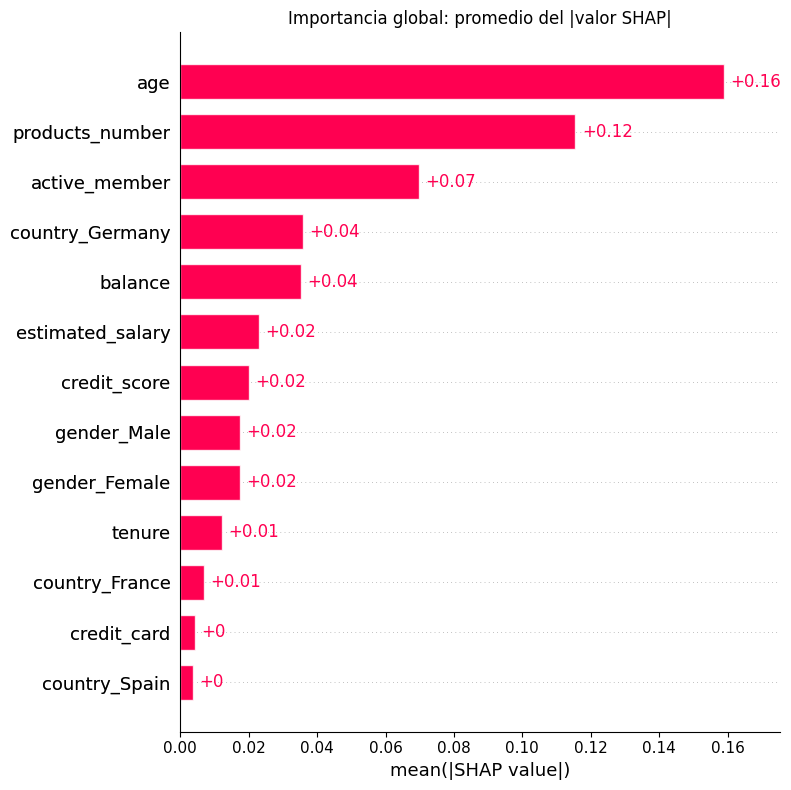

In [28]:
shap.plots.bar(shap_rf, max_display=13, show=False)
plt.title("Importancia global: promedio del |valor SHAP|")
plt.tight_layout()
plt.show()

La edad es la variable más importante (mueve la predicción 0,16 en promedio), seguida del número de productos (0,12) y de ser miembro activo (0,07). Les siguen ser de Alemania y el saldo (0,04 cada una). Las demás variables tienen un peso pequeño, y la tarjeta de crédito y ser de España prácticamente no influyen. Este orden coincide con lo que encontramos en el EDA. Las variables con relaciones más fuertes con el churn son las que el modelo más usa.

**Dirección de los efectos.** El gráfico *beeswarm* muestra un punto por cliente y variable. La posición horizontal es el valor SHAP (a la derecha sube el riesgo, a la izquierda lo baja) y el color indica el valor de la variable para ese cliente (rojo para valores altos, azul para valores bajos). Así se ve, por ejemplo, si los clientes de mayor edad (puntos rojos) tienden a estar a la derecha.

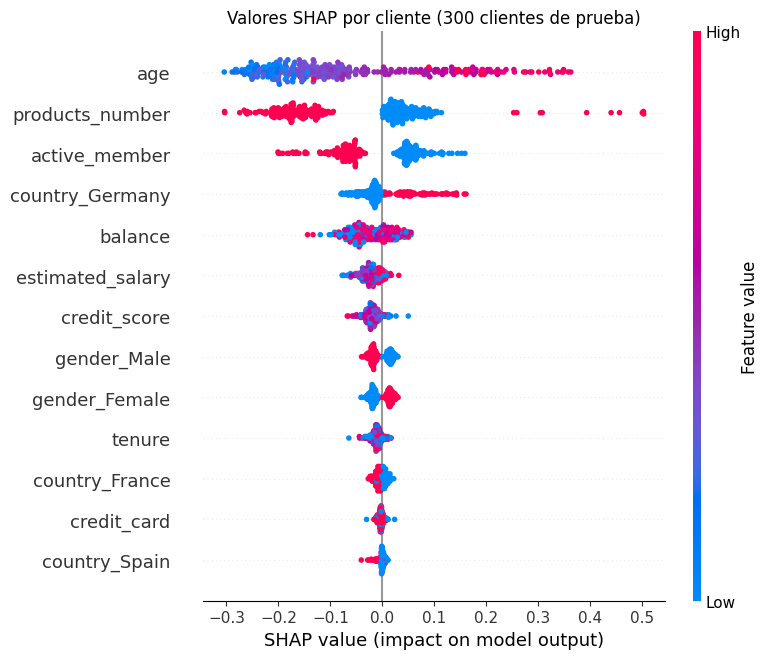

In [29]:
shap.plots.beeswarm(shap_rf, max_display=13, show=False)
plt.title("Valores SHAP por cliente (300 clientes de prueba)")
plt.tight_layout()
plt.show()

**Interpretación**

* **`age`.** Los clientes jóvenes (azul) tienen valores SHAP negativos, es decir, la edad les reduce el riesgo. Los de edad media y alta (morado y rojo) están mayoritariamente a la derecha. Algunos puntos rojos quedan más cerca de 0, lo que refleja que el efecto no es monótono y que el riesgo vuelve a bajar en los clientes de mayor edad.
* **`products_number`.** Los clientes con 1 producto (azul) tienen un aumento moderado del riesgo. El grupo rojo grande a la izquierda, entre -0,1 y -0,25, corresponde a los clientes con 2 productos, para quienes esta variable reduce el riesgo. Los pocos puntos rojos aislados a la derecha, entre +0,25 y +0,5, son los clientes con 3 o 4 productos (cerca del 3% de los clientes), que tienen los valores SHAP más altos de todo el gráfico.
* **`active_member`.** Ser activo (rojo) baja el riesgo y ser inactivo (azul) lo sube.
* **`country_Germany`.** Ser de Alemania (rojo) sube el riesgo.
* **Género.** Ser mujer sube ligeramente el riesgo y ser hombre lo baja, con efectos pequeños.

### 4.3 Análisis de predicciones individuales

Ahora examinamos tres clientes de prueba, uno de cada tipo de resultado relevante para la campaña:
* **Verdadero positivo.** Abandonó y el modelo lo detectó.
* **Falso negativo.** Abandonó y el modelo **no** lo detectó (un cliente que se pierde sin intentar retenerlo).
* **Falso positivo.** No abandonó, pero el modelo lo señaló como en riesgo (un contacto innecesario).

En cada grupo elegimos el caso **más extremo**, es decir, el abandono detectado con mayor probabilidad, el abandono no detectado con menor probabilidad y la falsa alarma con mayor probabilidad. Los casos extremos son los más útiles para entender en qué se apoya el modelo y en qué situaciones se equivoca con más seguridad.

In [30]:
pred_rf_prueba = predicciones["RF originales"]
resultado = pd.Series(np.select(
    [(y_prueba == 1) & (pred_rf_prueba == 1), (y_prueba == 1) & (pred_rf_prueba == 0),
     (y_prueba == 0) & (pred_rf_prueba == 1)],
    ["Verdadero positivo", "Falso negativo", "Falso positivo"], default="Verdadero negativo",
), index=X_test.index)
probabilidad = pd.Series(prob_rf_prueba, index=X_test.index)

casos = {
    "Verdadero positivo": probabilidad[resultado == "Verdadero positivo"].idxmax(),
    "Falso negativo": probabilidad[resultado == "Falso negativo"].idxmin(),
    "Falso positivo": probabilidad[resultado == "Falso positivo"].idxmax(),
}

tabla_casos = X_test.loc[list(casos.values()), atributos_rf].copy()
tabla_casos.insert(0, "caso", list(casos.keys()))
tabla_casos["churn_real"] = y_test.loc[list(casos.values())].values
tabla_casos["prob_predicha"] = probabilidad.loc[list(casos.values())].values
tabla_casos

,caso,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_France,country_Germany,country_Spain,gender_Female,gender_Male,churn_real,prob_predicha
5190,Verdadero positivo,734.000,54.000,3.000,0.000,1,1,0,130805.540,1,0,0,1,0,1,0.980
8211,Falso negativo,682.000,NaN,6.000,0.000,2,0,1,134158.090,1,0,0,0,1,1,0.010
2117,Falso positivo,698.000,51.000,2.000,111018.980,1,1,0,86410.280,0,1,0,1,0,0,0.970


Los tres clientes elegidos:
* **Verdadero positivo (cliente 5190).** Mujer de 54 años de Francia, inactiva, con 1 producto. El modelo le asigna 0,98 y efectivamente abandonó.
* **Falso negativo (cliente 8211).** Hombre de Francia, activo, con 2 productos y saldo 0. El modelo le asigna 0,01, pero abandonó. Un detalle importante es que **su edad es faltante** (`NaN`) y el modelo la recibió imputada con la mediana del entrenamiento, 37 años.
* **Falso positivo (cliente 2117).** Mujer de 51 años de Alemania, inactiva, con 1 producto. El modelo le asigna 0,97, pero no abandonó.

**Explicación** El gráfico parte del valor base (0.5) y suma, una por una, las contribuciones de las variables hasta llegar a la probabilidad predicha del cliente (arriba, `f(x)`). Las barras rojas suben el riesgo y las azules lo bajan. También verificamos numéricamente que el valor base más la suma de los valores SHAP es igual a la probabilidad predicha.

Verdadero positivo: valor base + suma SHAP = 0.980, probabilidad del modelo = 0.980


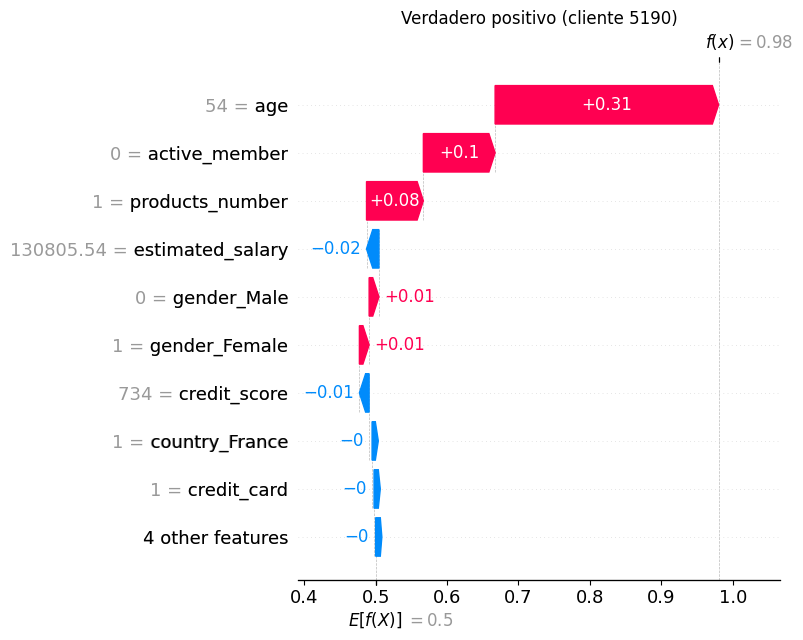

Falso negativo: valor base + suma SHAP = 0.010, probabilidad del modelo = 0.010


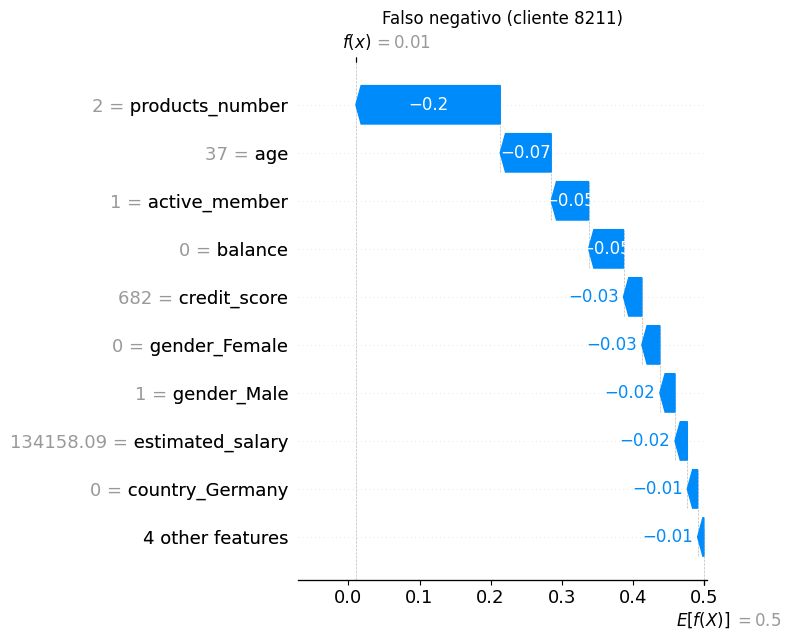

Falso positivo: valor base + suma SHAP = 0.970, probabilidad del modelo = 0.970


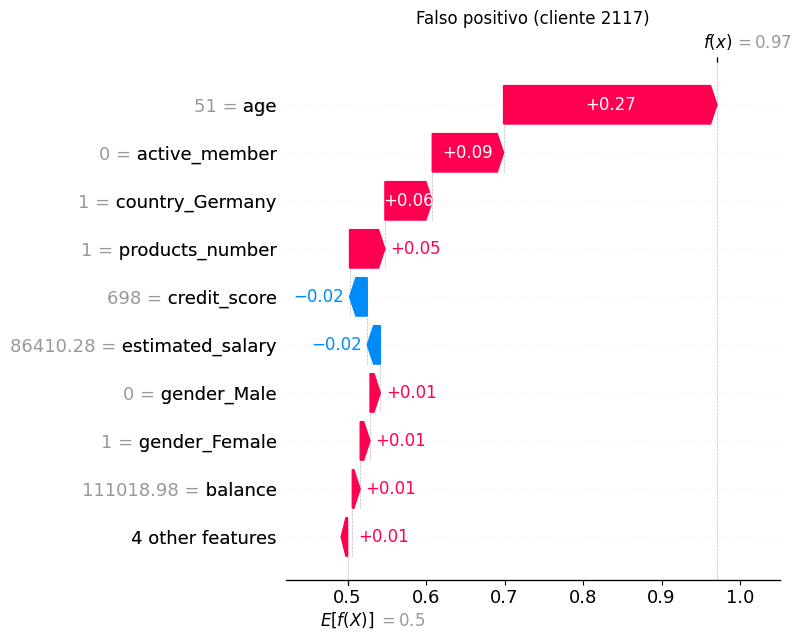

In [31]:
shap_casos = calcular_shap(X_prueba_imp.loc[list(casos.values())])

for i, (caso, indice) in enumerate(casos.items()):
    reconstruida = shap_casos.base_values[i] + shap_casos.values[i].sum()
    print(f"{caso}: valor base + suma SHAP = {reconstruida:.3f}, "
          f"probabilidad del modelo = {probabilidad[indice]:.3f}")
    shap.plots.waterfall(shap_casos[i], max_display=10, show=False)
    plt.title(f"{caso} (cliente {indice})")
    plt.tight_layout()
    plt.show()

En los tres casos se verifica que el valor base (0,5) más la suma de los valores SHAP reproduce exactamente la probabilidad del modelo.

**Verdadero positivo.** La edad (54 años) es lo que más sube el riesgo (+0,31), seguida de ser inactiva (+0,10) y tener un solo producto (+0,08). Es el perfil de mayor riesgo que identificamos en las curvas ICE, con edad entre 50 y 60 años e inactividad.

**Falso negativo.** Todo empuja la prob hacia abajo, tener 2 productos (-0,20), la edad imputada de 37 años (-0,07), ser activo (-0,05) y no tener saldo (-0,05). Para el modelo este cliente tiene el perfil de un cliente que no se va. Hay dos posibles razones del error:
1. **El dato faltante.** El modelo vio una edad de 37 años que no es real. Si el cliente fuera mayor, su riesgo podría ser mucho más alto. Este caso muestra un costo concreto de imputar con la mediana, pues los clientes con edad faltante quedan "disfrazados" de clientes de edad promedio.
2. **Información que no tenemos.** Este cliente pudo irse por razones que no están en los datos, como una mala experiencia de servicio o una mejor oferta de otro banco. Ningún modelo puede detectar lo que los datos no registran.

**Falso positivo.** El patrón es casi idéntico al del verdadero positivo, con edad de 51 años (+0,27), inactiva (+0,09), de Alemania (+0,06) y con 1 producto (+0,05). Con la información disponible, esta clienta no se distingue de los clientes que abandonan.

#### **Explicación LIME de cada caso** 
LIME explica una predicción de otra forma. Genera muchos clientes "vecinos" alterando ligeramente los valores del cliente, le pide al modelo que los prediga y ajusta un modelo lineal simple que imite al Random Forest **solo en esa zona**. Los coeficientes de ese modelo lineal son la explicación.


Algunos detalles de la configuración:
* Le indicamos cuáles variables son categóricas o binarias (país, género, tarjeta de crédito, miembro activo), para que al generar vecinos las trate como categorías y no como números continuos.
* Usamos `discretize_continuous=False`, como en la práctica del curso, para evitar un error conocido de LIME con variables que tienen muchos valores repetidos, como `balance`, que es 0 para un tercio de los clientes.
* Mostramos las 6 variables más influyentes.

Además de la explicación, revisamos la **fidelidad local**. `score` es el R² del modelo lineal en la vecindad (qué tan bien imita al Random Forest alrededor del cliente) y `local_pred` es la probabilidad que predice ese modelo lineal, que debería parecerse a la del Random Forest.

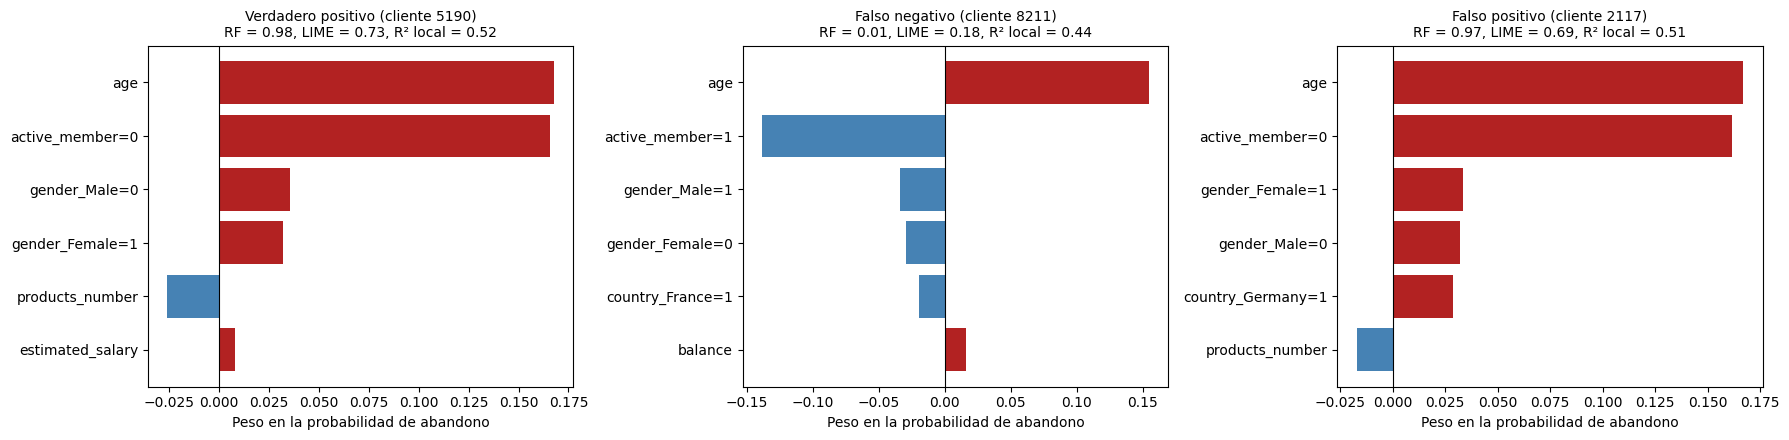

In [32]:
from lime.lime_tabular import LimeTabularExplainer

variables_categoricas = ["credit_card", "active_member", "country_France", "country_Germany",
                         "country_Spain", "gender_Female", "gender_Male"]

explicador_lime = LimeTabularExplainer(
    training_data=X_entrenamiento_imp.to_numpy(),
    feature_names=atributos_rf,
    class_names=["Se queda", "Se va"],
    categorical_features=[atributos_rf.index(v) for v in variables_categoricas],
    mode="classification",
    discretize_continuous=False,
    random_state=SEED,
)


def predecir_abandono(X):
    """Función de predicción para LIME: recibe un arreglo y devuelve las probabilidades."""
    return modelo_rf.predict_proba(pd.DataFrame(X, columns=atributos_rf))


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (caso, indice) in zip(axes, casos.items()):
    explicacion = explicador_lime.explain_instance(
        X_prueba_imp.loc[indice].to_numpy(), predecir_abandono, num_features=6, labels=(1,))
    pesos = explicacion.as_list(label=1)[::-1]
    ax.barh([nombre for nombre, _ in pesos], [peso for _, peso in pesos],
            color=["firebrick" if peso > 0 else "steelblue" for _, peso in pesos])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{caso} (cliente {indice})\n"
                 f"RF = {probabilidad[indice]:.2f}, LIME = {explicacion.local_pred[0]:.2f}, "
                 f"R² local = {explicacion.score:.2f}", fontsize=10)
    ax.set_xlabel("Peso en la probabilidad de abandono")
plt.tight_layout()
plt.show()

**Interpretación de LIME y comparación con SHAP**

* **Coincidencias.** En los tres clientes LIME destaca las mismas variables principales que SHAP, la edad y ser miembro activo, y en menor medida el género y el país.
* **El número de productos.** LIME le da un peso pequeño y negativo en el verdadero positivo y en el falso positivo, y en el falso negativo ni siquiera aparece entre las 6 variables más influyentes, mientras que SHAP lo ubica entre las más importantes en los tres casos. La razón puede ser que LIME aproxima al modelo con una **línea recta**, y la relación entre los productos y el churn tiene forma de U.
* **La edad en el falso negativo.** SHAP dice que la edad de este cliente (37 años) **baja** su riesgo, y LIME le da un peso **positivo**. SHAP mide cuánto aporta el valor de la variable de este cliente frente al cliente promedio, y LIME mide la pendiente local. Es decir, "si este cliente tuviera más edad, ¿su riesgo subiría?". Ambas cosas son ciertas a la vez. Tener 37 años lo ubica por debajo del riesgo promedio, y si tuviera más edad su riesgo aumentaría.
* **Fidelidad local.** El R² local está entre 0,44 y 0,52, y la predicción de LIME se aleja bastante de la del Random Forest (por ejemplo, 0,73 frente a 0,98 en el verdadero positivo). El modelo lineal de LIME imita solo de forma aproximada al Random Forest alrededor de estos clientes.

En este problema, SHAP ofrece explicaciones más confiables. LIME es útil como verificación independiente y para modelos donde no existe un explicador exacto.

### 4.4 Comparación con los otros modelos

Hasta ahora interpretamos el modelo elegido. Para entender mejor por qué los modelos tienen desempeños distintos, comparamos cómo funcionan los otros dos candidatos principales, el **Gradient Boosting** con atributos originales (el otro ensamble) y la **regresión logística** con atributos ampliados (el mejor modelo básico).

#### Coeficientes de la regresión logística

La regresión logística es un modelo interpretable por sí mismo, pues cada variable tiene un coeficiente que indica cuánto cambia el logaritmo de las probabilidades (*log-odds*) de abandonar cuando la variable aumenta en una unidad. Como las variables están estandarizadas, una unidad equivale a una desviación estándar, así que los coeficientes se pueden comparar entre sí. Un coeficiente mayor en valor absoluto indica una variable con más peso.

* Un coeficiente **positivo** indica que valores más altos de la variable aumentan el riesgo de churn.
* Un coeficiente **negativo** indica que lo disminuyen.

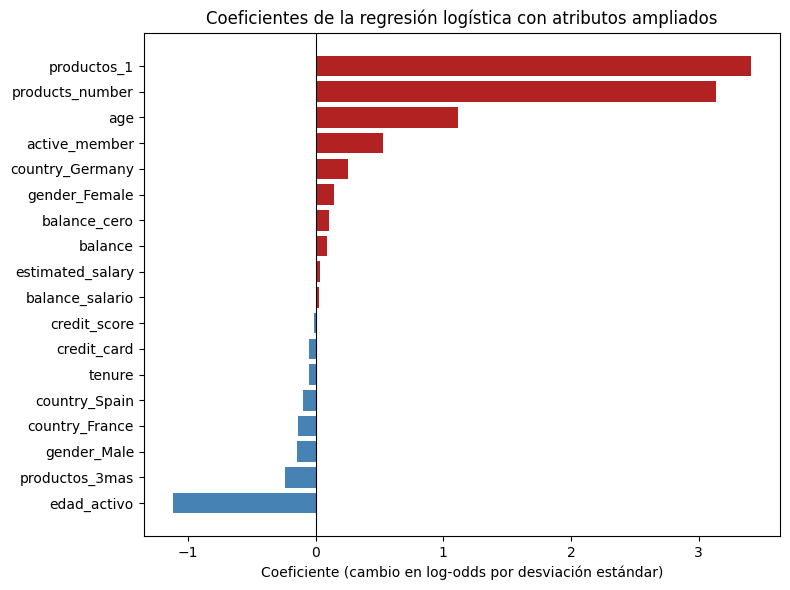

In [33]:
modelo_rl, atributos_rl = CANDIDATOS["RL ampliados"]
coeficientes = pd.Series(modelo_rl.named_steps["modelo"].coef_[0], index=atributos_rl).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(coeficientes.index, coeficientes.values,
        color=["firebrick" if c > 0 else "steelblue" for c in coeficientes.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (cambio en log-odds por desviación estándar)")
ax.set_title("Coeficientes de la regresión logística con atributos ampliados")
plt.tight_layout()
plt.show()

Los coeficientes muestran cómo la regresión logística usa las variables derivadas para imitar patrones que los árboles capturan por sí solos.

* **Número de productos.** `productos_1` (+3,4) y `products_number` (+3,1) tienen los coeficientes más grandes, y `productos_3mas` uno pequeño y negativo (-0,24). Leídos por separado parecen contradictorios, pero hay que interpretarlos juntos. `products_number` hace que el riesgo suba a medida que aumentan los productos, lo que da un riesgo alto con 3 o 4, y `productos_1` le suma un riesgo adicional a quien tiene un solo producto. El resultado combinado es la curva en U, con el riesgo más bajo en 2 productos.
* **Edad y actividad.** `age` tiene un coeficiente positivo (+1,1) y `edad_activo` uno negativo del mismo tamaño (-1,1). Esto significa que en los clientes inactivos la edad aumenta mucho el riesgo, mientras que en los activos ese aumento es bastante menor. Es la misma interacción que mostraron las curvas ICE coloreadas por actividad. Por esta razón, el coeficiente positivo de `active_member` (+0,5) no significa que ser activo aumente el riesgo, porque su efecto real depende de la edad a través de `edad_activo`.
* **País y género.** Ser de Alemania (+0,25) y ser mujer (+0,14) aumentan el riesgo, y ser de Francia o España lo reduce levemente.
* **Variables casi sin efecto.** El saldo, el salario, la razón entre saldo y salario, el puntaje crediticio, la antigüedad y la tarjeta de crédito tienen coeficientes cercanos a 0.

#### Importancia de las variables en los tres modelos

Calculamos los valores SHAP de los tres modelos sobre los mismos 300 clientes de la sección 4.2:
* **Random Forest.** Los valores ya calculados.
* **Gradient Boosting.** `TreeExplainer`, igual que en el Random Forest.
* **Regresión logística.** `LinearExplainer`, que calcula los valores SHAP de forma exacta para modelos lineales.

Los valores SHAP de cada modelo están en unidades distintas. En el Random Forest son probabilidades y en el Gradient Boosting y la regresión logística son log-odds. Por eso, para comparar, expresamos la importancia de cada variable como **porcentaje de la importancia total** de su modelo.

La regresión logística usa 18 variables y los ensambles 13. Las variables derivadas solo aparecen en la regresión logística.

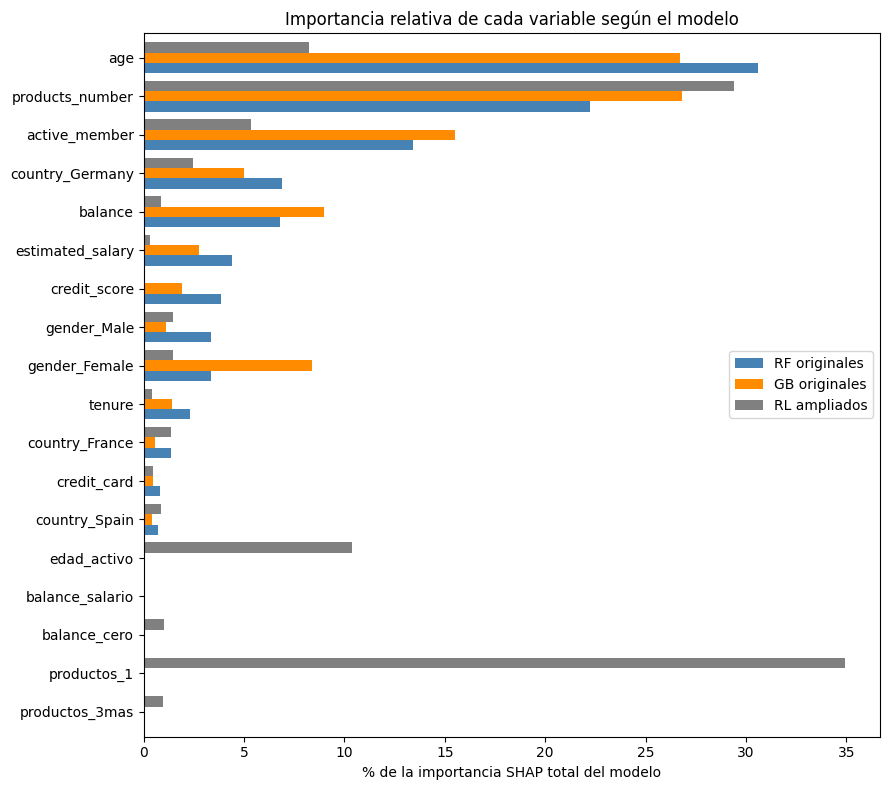

,RF originales,GB originales,RL ampliados
age,30.600,26.700,8.200
products_number,22.200,26.800,29.400
active_member,13.400,15.500,5.300
country_Germany,6.900,5.000,2.400
balance,6.800,9.000,0.900
estimated_salary,4.400,2.800,0.300
credit_score,3.900,1.900,0.100
gender_Male,3.300,1.100,1.400
gender_Female,3.300,8.400,1.400
tenure,2.300,1.400,0.400


In [34]:
from sklearn.linear_model import LogisticRegression as _RegresionLogistica


def importancia_shap(nombre):
    """Calcula el porcentaje de importancia SHAP de cada variable de un candidato."""
    modelo, atributos = CANDIDATOS[nombre]
    preproceso = modelo[:-1]
    estimador = modelo.named_steps["modelo"]
    X_explicar = preproceso.transform(X_test.loc[X_shap.index, atributos])

    if isinstance(estimador, _RegresionLogistica):
        referencia = preproceso.transform(X_train[atributos].sample(100, random_state=SEED))
        explicador = shap.LinearExplainer(estimador, referencia)
    else:
        explicador = shap.TreeExplainer(estimador)

    valores = explicador(X_explicar).values
    if valores.ndim == 3:
        valores = valores[:, :, 1]
    importancia = pd.Series(np.abs(valores).mean(axis=0), index=atributos)
    return importancia / importancia.sum() * 100


importancias = pd.DataFrame({
    "RF originales": importancia_shap("RF originales"),
    "GB originales": importancia_shap("GB originales"),
    "RL ampliados": importancia_shap("RL ampliados"),
}).fillna(0).sort_values("RF originales")

fig, ax = plt.subplots(figsize=(9, 8))
importancias.plot.barh(ax=ax, color=["steelblue", "darkorange", "gray"], width=0.8)
ax.set_xlabel("% de la importancia SHAP total del modelo")
ax.set_title("Importancia relativa de cada variable según el modelo")
plt.tight_layout()
plt.show()

importancias.sort_values("RF originales", ascending=False).round(1)

* **Las tres variables principales coinciden.** En los tres modelos, el número de productos, la edad y la actividad del cliente concentran la mayor parte de la importancia, con 66% en el Random Forest, 69% en el Gradient Boosting y 89% en la regresión logística si se suman sus variables derivadas.
* **Diferencias entre los ensambles.** El Random Forest le da más peso a la edad (31%), mientras que el Gradient Boosting reparte casi por igual entre la edad y los productos (27% cada una). El Gradient Boosting usa algo más el saldo (9% frente a 7%) y concentra el género en `gender_Female` (8%). El Random Forest reparte el género entre las dos columnas, que contienen la misma información.
* **La regresión logística** concentra casi dos tercios de su importancia en las variables de productos (`productos_1` y `products_number`) y expresa buena parte del efecto de la edad a través de la interacción `edad_activo`. Le da muy poco peso al país y al saldo comparado con los ensambles.
* **Variables derivadas poco útiles.** `balance_salario`, `balance_cero` y `productos_3mas` tienen una importancia cercana a 0 en la regresión logística. Las variables derivadas que realmente aportaron fueron `productos_1` y `edad_activo`.

#### Efecto de la edad y de los productos en los dos ensambles

Los dos ensambles usan las mismas 13 variables, así que podemos comparar directamente sus curvas PDP. Las calculamos sobre los mismos 200 clientes de la sección 4.1.

No incluimos la regresión logística ampliada en esta comparación. Al variar `products_number` en una curva PDP, las variables derivadas `productos_1` y `productos_3mas` quedarían con sus valores originales, y el modelo recibiría combinaciones imposibles (por ejemplo, 3 productos con `productos_1 = 1`). Su comportamiento ya se ve en los coeficientes.

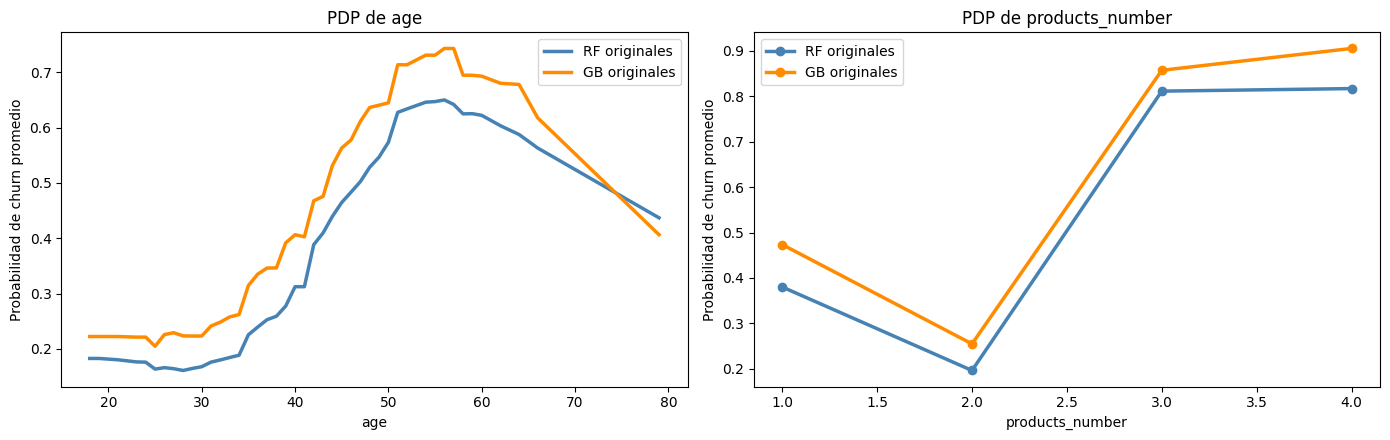

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, variable in zip(axes, ["age", "products_number"]):
    for nombre, color in [("RF originales", "steelblue"), ("GB originales", "darkorange")]:
        modelo, atributos = CANDIDATOS[nombre]
        pdp = partial_dependence(modelo, X_ice[atributos], features=[variable],
                                 kind="average", response_method="predict_proba")
        ax.plot(pdp["grid_values"][0], pdp["average"][0], color=color, linewidth=2.5,
                marker="o" if variable == "products_number" else None, label=nombre)
    ax.set_xlabel(variable)
    ax.set_ylabel("Probabilidad de churn promedio")
    ax.set_title(f"PDP de {variable}")
    ax.legend()
plt.tight_layout()
plt.show()

Los dos ensambles aprendieron prácticamente las mismas formas. El riesgo por edad sube desde los 35 años hasta un máximo entre los 55 y los 57 años y luego baja, y los productos forman la misma U. La diferencia es de **nivel**, porque las curvas del Gradient Boosting están casi siempre por encima de las del Random Forest. Por ejemplo, con 1 producto el riesgo promedio es 0,47 en el Gradient Boosting y 0,38 en el Random Forest, y en el pico de edad es cerca de 0,74 frente a 0,65.

Esto explica los resultados del punto 3. Como ambos modelos ordenan a los clientes de forma parecida, tienen el mismo ROC-AUC y PR-AUC. Pero como el Gradient Boosting asigna probabilidades más altas, con el mismo umbral de 0,5 marca a más clientes como en riesgo, y por eso tiene más recall y menos precisión que el Random Forest.

#### Los tres clientes según cada modelo

Por último, revisamos qué probabilidad le asigna cada candidato a los tres clientes de la sección 4.3. Esto permite ver si los errores del Random Forest son propios de ese modelo o si los demás modelos también se equivocan con esos clientes.

In [36]:
posiciones = [X_test.index.get_loc(indice) for indice in casos.values()]
probabilidades_casos = pd.DataFrame(
    {nombre: probabilidades[nombre][posiciones] for nombre in CANDIDATOS},
    index=[f"{caso} (cliente {indice})" for caso, indice in casos.items()],
)
probabilidades_casos.insert(0, "churn_real", y_test.loc[list(casos.values())].values)
probabilidades_casos.round(3)

,churn_real,RL originales,RL ampliados,RF originales,GB originales
Verdadero positivo (cliente 5190),1,0.782,0.918,0.980,0.966
Falso negativo (cliente 8211),1,0.187,0.155,0.010,0.037
Falso positivo (cliente 2117),0,0.884,0.947,0.970,0.947


Los cuatro modelos coinciden en los tres clientes. Todos le asignan un riesgo alto al verdadero positivo (entre 0,78 y 0,98), un riesgo bajo al falso negativo (entre 0,01 y 0,19) y un riesgo alto al falso positivo (entre 0,88 y 0,97).

Los errores no son propios del Random Forest, porque ningún modelo detecta al cliente 8211 y todos se equivocan con la clienta 2117. Esto refuerza la conclusión de la sección 4.3, según la cual estos errores vienen de los datos, ya sea por información que no está disponible o por información incompleta como la edad faltante, y no de la elección del modelo. Para reducirlos habría que mejorar los datos más que cambiar de algoritmo.

### 4.5 Conclusiones

#### Comparación de las técnicas de interpretación

| Técnica | Alcance | Pregunta que responde | Costo computacional | Estabilidad | Limitaciones |
|---|---|---|---|---|---|
| **ICE y PDP** | Global, con una curva por cliente | ¿Cómo cambia el riesgo al variar una variable? | Bajo | Alta | Al variar una sola variable puede generar clientes irreales, por ejemplo cuando hay variables derivadas o muy correlacionadas |
| **SHAP** | Global y local | ¿Cuánto aporta cada variable a cada predicción y en qué dirección? | Medio, exacto y rápido para árboles y modelos lineales | Alta, porque `TreeExplainer` siempre da el mismo resultado | Sus unidades dependen del modelo y la escala de colores del beeswarm puede confundir en variables con pocos valores |
| **LIME** | Local | ¿Qué variables explican la predicción de un cliente según un modelo lineal aproximado? | Medio | Baja, porque depende del muestreo aleatorio de vecinos | Aproxima con una recta, por lo que no captura relaciones en U, y su fidelidad local fue baja (R² cercano a 0,5) |

Las tres técnicas coinciden en que la edad, la actividad del cliente y el número de productos son las variables que más influyen en el modelo. Para explicarle al banco el riesgo de un cliente concreto, SHAP es la técnica más adecuada, porque su explicación suma exactamente la predicción del modelo y muestra en una sola gráfica qué empuja el riesgo hacia arriba y qué hacia abajo. Las curvas ICE son las más útiles para comunicar los patrones generales a personas sin formación técnica.

Ninguna de las tres técnicas demuestra relaciones causales. Todas describen cómo el modelo usa las variables para predecir, y el modelo a su vez solo aprendió asociaciones presentes en los datos.

#### ¿Cómo funciona el modelo?

El Random Forest estima el riesgo de abandono de un cliente apoyándose sobre todo en tres características, que juntas explican cerca de dos tercios de sus decisiones.

1. **La edad.** El riesgo es bajo hasta los 35 años, sube con fuerza entre los 40 y los 50, alcanza su máximo entre los 52 y los 57 años y baja después de los 60.
2. **El número de productos.** Tener 2 productos es la situación de menor riesgo, tener 1 producto aumenta el riesgo de forma moderada y tener 3 o 4 productos lo dispara, con probabilidades por encima de 0,8.
3. **La actividad del cliente.** Los clientes inactivos tienen más riesgo, y además la inactividad amplifica el efecto de la edad. Un cliente mayor de 50 años e inactivo es el perfil de mayor riesgo, mientras que un cliente de la misma edad que usa activamente el banco tiene un riesgo mucho menor.

En un segundo nivel, el modelo aumenta el riesgo de los clientes de Alemania y, ligeramente, el de las mujeres. El saldo influye poco por sí solo, y el salario estimado, el puntaje crediticio, la antigüedad y la tarjeta de crédito prácticamente no cambian sus predicciones.


**Dónde se equivoca.** Los errores más grandes ocurren con clientes cuyo perfil no coincide con su comportamiento. Hay clientes con perfil de bajo riesgo que abandonan, y clientes con perfil de alto riesgo que se quedan. Todos los modelos cometen los mismos errores con esos clientes, lo que indica que la causa está en la información disponible y no en el algoritmo. Además, la imputación con la mediana puede ocultar el riesgo de clientes con datos faltantes, como el cliente al que el modelo vio con 37 años sin conocer su edad real.